# EDA na Prática

Nas aulas 9 e 10 vimos os quatro princípios da EDA (estrutural, distribucional, relacional e detecção de outliers/anomalias), como tratar dados ausentes e outliers, e como fazer análise descritiva, bivariada e multivariada. Hoje é a hora de **aplicarmos na prática**. Durante a primeira hora da aula, serão apresentadas as técnicas no dataset *Heart Disease* (UCI) e depois **cada aluno** irá aplicar as técnicas no dataset que foi escolhido semana passada.

*Relembrando*: a EDA não é uma linha reta

A EDA costuma ser apresentada como uma sequência de etapas (estrutura → tratamento → descrição → relação), mas na prática ela é **iterativa**: às vezes tratamos um outlier, olhamos a estatística descritiva de novo, e percebemos que precisa voltar atrás. Hoje vamos deixar isso explícito: olhamos a estatística descritiva **antes** de tratar dados ausentes/outliers (pra saber *como* tratar) e **depois** (pra confirmar o efeito do tratamento).

## Como funcionará a atividade

- **Duração:** ~1h40min
- **Formato:** individual
- **Passo 1:** acompanhem a demonstração no dataset Heart Disease.
- **Passo 2:** importem o dataset que vocês escolheram e enviaram anteriormente.
- **Passo 3:** repliquem o mesmo ciclo no dataset escolhido, respondendo às perguntas guiadas.
- **Uso de IA:** permitido, conforme o Plano de Ensino — documentem na seção final.

## Setup de Bibliotecas e Dados

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)

COR_NEUTRA = "lightgray"     # convenção: cinza-claro pra tudo que é "pano de fundo" genérico
COR_CONTEXTO = "#e9d4d0"    # rosa-claro pra pano de fundo / classe de referência
COR_DESTAQUE = "#2d223a"    # roxo pra classe de interesse / "o personagem da história"
COR_ALERTA = "tab:red"       # exceção deliberada: outliers/pontos de atenção

## Carregando o Dataset

In [ ]:
import pandas as pd

df_student_exam_performance = pd.read_csv('/content/drive/My Drive/student_exam_performance.csv')

display(df_student_exam_performance.head())

,student_id,age,gender,education_level,school_type,family_income,parent_education,urban_rural,previous_exam_score,previous_gpa,...,exam_difficulty,exam_preparation_days,questions_attempted,questions_correct,time_management_score,exam_anxiety_level,exam_score,performance_grade,pass_status,performance_level
0,STU_000001,20,Female,High School,Public,Middle,NaN,Rural,78.36,2.95,...,Medium,27,95,86,NaN,9.39,90.40,A,Pass,High
1,STU_000002,17,Male,High School,Public,Middle,NaN,Suburban,73.40,2.89,...,Easy,4,100,86,87.17,6.31,86.21,A,Pass,High
2,STU_000003,18,Other,Undergraduate,Public,Middle,Master,Urban,82.76,3.35,...,Easy,28,96,74,63.77,9.87,76.11,B,Pass,Medium
3,STU_000004,20,Male,High School,Public,Middle,High School,Suburban,60.61,2.57,...,Medium,16,97,77,59.51,9.68,79.74,B,Pass,Medium
4,STU_000005,16,Female,High School,Private,High,Bachelor,Suburban,74.79,2.84,...,Medium,28,98,52,84.64,10.00,50.66,D,Pass,Low


## 1. Princípio Estrutural

Antes de qualquer análise, precisamos entender a "anatomia" dos dados: quantas linhas e colunas temos, que tipo de dado cada coluna guarda, se há valores faltantes e se há duplicadas.

**Antes de rodar:** o Heart Disease tem 13 variáveis preditoras (idade, sexo, tipo de dor no peito, pressão em repouso, colesterol, entre outras) mais o alvo (`num`, presença/grau de doença cardíaca). Quantas linhas vocês esperam que um dataset clínico como esse tenha — dezenas, centenas ou milhares de pacientes?

Para o nosso dataset de `student_exam_performance`, vamos analisar as dimensões e tipos de dados, buscando entender a estrutura inicial antes de qualquer tratamento.

### Dimensão e Tipos de Dados

In [ ]:
df_student_exam_performance.shape

(100000, 44)

In [ ]:
df_student_exam_performance.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 44 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   student_id                  100000 non-null  object 
 1   age                         100000 non-null  int64  
 2   gender                      100000 non-null  object 
 3   education_level             100000 non-null  object 
 4   school_type                 100000 non-null  object 
 5   family_income               100000 non-null  object 
 6   parent_education            93474 non-null   object 
 7   urban_rural                 100000 non-null  object 
 8   previous_exam_score         100000 non-null  float64
 9   previous_gpa                92207 non-null   float64
 10  attendance_percentage       90137 non-null   float64
 11  assignment_completion_rate  100000 non-null  float64
 12  class_participation         100000 non-null  object 
 13  study_hours_per

In [ ]:
df_student_exam_performance.describe()

,age,previous_exam_score,previous_gpa,attendance_percentage,assignment_completion_rate,study_hours_per_day,self_study_hours,private_tuition,online_learning_hours,practice_tests_completed,...,physical_activity_hours,stress_level,internet_access,online_course_hours,exam_preparation_days,questions_attempted,questions_correct,time_management_score,exam_anxiety_level,exam_score
count,100000.000000,100000.000000,92207.000000,90137.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,...,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,90387.000000,100000.000000,100000.000000
mean,17.005740,69.531033,2.780892,84.616882,69.724405,2.995725,2.094970,0.299800,2.004763,5.509170,...,2.487579,9.375640,0.918760,2.999453,15.501440,92.492150,57.298240,78.398551,8.927373,61.950072
std,1.999562,11.379108,0.478218,7.922485,12.127179,1.719466,1.266066,0.458173,2.005719,2.501131,...,2.413386,1.081613,0.273205,2.983732,8.644356,4.609376,15.028787,14.105155,1.354875,15.863644
min,14.000000,30.000000,1.000000,46.340000,20.000000,0.500000,0.250000,0.000000,0.000000,0.000000,...,0.000000,5.000000,0.000000,0.000000,1.000000,85.000000,0.000000,17.030000,1.000000,0.000000
25%,15.000000,61.820000,2.460000,79.210000,61.480000,1.720000,1.170000,0.000000,0.580000,4.000000,...,0.720000,9.000000,1.000000,0.860000,8.000000,88.000000,47.000000,68.790000,8.220000,51.240000
50%,17.000000,69.530000,2.780000,84.750000,69.570000,2.670000,1.840000,0.000000,1.380000,5.000000,...,1.730000,10.000000,1.000000,2.080000,16.000000,92.000000,57.000000,79.000000,9.490000,61.960000
75%,19.000000,77.232500,3.110000,90.170000,77.920000,3.910000,2.730000,1.000000,2.770000,7.000000,...,3.480000,10.000000,1.000000,4.150000,23.000000,96.000000,67.000000,89.210000,10.000000,72.730000
max,20.000000,100.000000,4.000000,100.000000,100.000000,12.000000,10.000000,1.000000,15.000000,20.000000,...,12.000000,10.000000,1.000000,20.000000,30.000000,100.000000,100.000000,100.000000,10.000000,100.000000


### Duplicadas

In [ ]:
df_student_exam_performance.duplicated().sum()

np.int64(0)

### Renomeando o atributo alvo para facilitar a interpretação

O dataset original registra `num` de 0 (sem doença) a 4 (graus diferentes de doença). Pra hoje, vamos simplificar para uma variável binária, presença ou ausência de doença cardíaca, já que é essa a distinção que vamos usar nas cores ao longo da aula (rosa = sem doença, roxo = com doença).

In [ ]:
import numpy as np

df_student_exam_performance.head()

,student_id,age,gender,education_level,school_type,family_income,parent_education,urban_rural,previous_exam_score,previous_gpa,...,exam_difficulty,exam_preparation_days,questions_attempted,questions_correct,time_management_score,exam_anxiety_level,exam_score,performance_grade,pass_status,performance_level
0,STU_000001,20,Female,High School,Public,Middle,NaN,Rural,78.36,2.95,...,Medium,27,95,86,NaN,9.39,90.40,A,Pass,High
1,STU_000002,17,Male,High School,Public,Middle,NaN,Suburban,73.40,2.89,...,Easy,4,100,86,87.17,6.31,86.21,A,Pass,High
2,STU_000003,18,Other,Undergraduate,Public,Middle,Master,Urban,82.76,3.35,...,Easy,28,96,74,63.77,9.87,76.11,B,Pass,Medium
3,STU_000004,20,Male,High School,Public,Middle,High School,Suburban,60.61,2.57,...,Medium,16,97,77,59.51,9.68,79.74,B,Pass,Medium
4,STU_000005,16,Female,High School,Private,High,Bachelor,Suburban,74.79,2.84,...,Medium,28,98,52,84.64,10.00,50.66,D,Pass,Low


O dataset original `df_student_exam_performance` contém uma coluna `pass_status` que indica se o aluno foi 'Pass' ou 'Fail'. Vamos usar essa coluna como nossa variável alvo para a análise.

In [ ]:
import pandas as pd

df_student_exam_performance = pd.read_csv('/content/drive/My Drive/student_exam_performance.csv')

display(df_student_exam_performance.head())

,student_id,age,gender,education_level,school_type,family_income,parent_education,urban_rural,previous_exam_score,previous_gpa,...,exam_difficulty,exam_preparation_days,questions_attempted,questions_correct,time_management_score,exam_anxiety_level,exam_score,performance_grade,pass_status,performance_level
0,STU_000001,20,Female,High School,Public,Middle,NaN,Rural,78.36,2.95,...,Medium,27,95,86,NaN,9.39,90.40,A,Pass,High
1,STU_000002,17,Male,High School,Public,Middle,NaN,Suburban,73.40,2.89,...,Easy,4,100,86,87.17,6.31,86.21,A,Pass,High
2,STU_000003,18,Other,Undergraduate,Public,Middle,Master,Urban,82.76,3.35,...,Easy,28,96,74,63.77,9.87,76.11,B,Pass,Medium
3,STU_000004,20,Male,High School,Public,Middle,High School,Suburban,60.61,2.57,...,Medium,16,97,77,59.51,9.68,79.74,B,Pass,Medium
4,STU_000005,16,Female,High School,Private,High,Bachelor,Suburban,74.79,2.84,...,Medium,28,98,52,84.64,10.00,50.66,D,Pass,Low


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import pandas as pd

df = df_student_exam_performance.copy()

TARGET_VARIABLE = 'pass_status'
PASS_LABEL = 'Pass'
FAIL_LABEL = 'Fail'

COR_CONTEXTO_NEW = "#b3e0b3"
COR_DESTAQUE_NEW = "#e0b3b3"

df[TARGET_VARIABLE] = df[TARGET_VARIABLE].replace({'Pass': PASS_LABEL, 'Fail': FAIL_LABEL})

VARS_QUANT = ['age', 'previous_exam_score', 'previous_gpa', 'attendance_percentage', 'assignment_completion_rate', 'study_hours_per_day', 'self_study_hours', 'private_tuition', 'online_learning_hours', 'practice_tests_completed', 'sleep_hours', 'daily_screen_time', 'physical_activity_hours', 'stress_level', 'internet_access', 'online_course_hours', 'exam_preparation_days', 'questions_attempted', 'questions_correct', 'time_management_score', 'exam_anxiety_level', 'exam_score']
VARS_QUALI = ['gender', 'education_level', 'school_type', 'family_income', 'parent_education', 'urban_rural', 'class_participation', 'study_consistency', 'study_environment', 'study_method', 'revision_frequency', 'notes_quality', 'sleep_quality', 'break_frequency', 'motivation_level', 'device_availability', 'educational_app_usage', 'exam_difficulty', 'performance_grade', 'pass_status', 'performance_level']

display(df.head())

,student_id,age,gender,education_level,school_type,family_income,parent_education,urban_rural,previous_exam_score,previous_gpa,...,exam_difficulty,exam_preparation_days,questions_attempted,questions_correct,time_management_score,exam_anxiety_level,exam_score,performance_grade,pass_status,performance_level
0,STU_000001,20,Female,High School,Public,Middle,NaN,Rural,78.36,2.95,...,Medium,27,95,86,NaN,9.39,90.40,A,Pass,High
1,STU_000002,17,Male,High School,Public,Middle,NaN,Suburban,73.40,2.89,...,Easy,4,100,86,87.17,6.31,86.21,A,Pass,High
2,STU_000003,18,Other,Undergraduate,Public,Middle,Master,Urban,82.76,3.35,...,Easy,28,96,74,63.77,9.87,76.11,B,Pass,Medium
3,STU_000004,20,Male,High School,Public,Middle,High School,Suburban,60.61,2.57,...,Medium,16,97,77,59.51,9.68,79.74,B,Pass,Medium
4,STU_000005,16,Female,High School,Private,High,Bachelor,Suburban,74.79,2.84,...,Medium,28,98,52,84.64,10.00,50.66,D,Pass,Low


## 2. Dados Faltantes

In [ ]:
df_student_exam_performance.isna().sum()

,0
student_id,0
age,0
gender,0
education_level,0
school_type,0
family_income,0
parent_education,6526
urban_rural,0
previous_exam_score,0
previous_gpa,7793


**Discussao:** Alguma feature tem dados ausentes nos seus dados?

*Resposta*:

#### Identificando o mecanismo de dados ausentes

**Conhecimento de Domínio**

No dataset atual temos dois features 'ca'e 'thal'com dados ausentes.

Pela fonte de dados observamos que:

* ca - número de vasos principais coloridos por fluroscopia
* thal - resultados do teste de estresse (talassemia)

*Como os dados foram coletados:*
- O conjunto de dados disponibilizado do UCI é um subconjunto de dados de experimentos publicados em 4 outros conjuntos médicos. Dos 4 conjuntos base para a construção deste dataset, apenas um deles foi utilizado por pesquisadores de Machine Learning anteriormente.

*Qual a natureza da fonte de dados:*
- Considerando que os dados são de pacientes médicos, sabemos que há desafios inerentes a lidar com pessoas nos estudos que podem não ter todos os resultados necessariamente.
- Além disso, o dataset condensa diferentes estudos (Cleveland, Hungary, Switzerland, and the VA Long Beach) de países diferentes, e alguns resultados, como os de *ca* e *thal*, podem ter sido faltantes devido a custos.

**As ausencias ocorrem juntas?**

Contar ausentes por coluna não conta a história toda: se duas colunas ficam ausentes **nas mesmas linhas**, isso é um indício de padrão sistemático (ex: um exame que não foi feito, afetando várias medidas de uma vez).



In [ ]:
cols_com_ausentes = df_student_exam_performance.columns[df_student_exam_performance.isna().any()].tolist()
print("Colunas com ausentes:", cols_com_ausentes)
print(df_student_exam_performance[cols_com_ausentes].isna().sum())

Colunas com ausentes: ['parent_education', 'previous_gpa', 'attendance_percentage', 'notes_quality', 'sleep_quality', 'device_availability', 'time_management_score']
parent_education         6526
previous_gpa             7793
attendance_percentage    9863
notes_quality            8407
sleep_quality            6994
device_availability      2965
time_management_score    9613
dtype: int64


Com poucos ausentes (no máximo poucas dezenas de linhas), uma correlação entre as colunas de ausência pode parecer precisa, mas na prática é calculada em cima de um poucos de casos, ou seja, número pequeno demais pra confiar no coeficiente. Aqui a contagem bruta (quantas linhas têm as duas ausências ao mesmo tempo) é mais honesta que uma correlação.

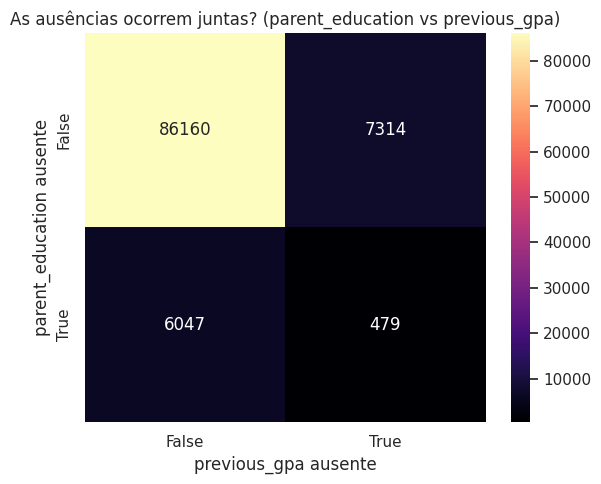

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

if len(cols_com_ausentes) >= 2:

    col_1 = cols_com_ausentes[0]
    col_2 = cols_com_ausentes[1]

    tabela_contingencia = pd.crosstab(df_student_exam_performance[col_1].isna(), df_student_exam_performance[col_2].isna(),
                rownames=[f"{col_1} ausente"], colnames=[f"{col_2} ausente"])

    fig, ax = plt.subplots(figsize=(6, 5))
    sns.heatmap(tabela_contingencia, annot=True, fmt="d", cmap="magma", ax=ax)
    ax.set_title(f"As ausências ocorrem juntas? ({col_1} vs {col_2})")
    plt.tight_layout()
    plt.show()

**Pra discutir:** quantas linhas têm as duas colunas ausentes ao mesmo tempo?

Isso muda a hipótese sobre o mecanismo de ausência (MCAR/MAR/MNAR), ou parecem eventos independentes?

Para as colunas 'parent_education' e 'previous_gpa', a análise de ausências no df_student_exam_performance.isna().sum() mostra 6526 e 7793 ausências, respectivamente. A célula LdjJkRVQ6Ts1 cria uma tabela de contingência para ver se essas ausências ocorrem juntas. Como o número de ausências é relativamente pequeno em relação ao total de 100.000 linhas, se a contagem de linhas com ambas as colunas ausentes for baixa, sugere que as ausências são eventos mais independentes. Isso não alteraria drasticamente a hipótese de mecanismo de ausência para MNAR; provavelmente permaneceríamos em MAR ou MCAR, pois não há um forte indício de que a ausência dependa do próprio valor que está faltando.

*Relembrando:*
- MCAR: Mecanismo Aleatório e sem viés
- MAR: Mecanismo Randômico e com viés possível de corrigir
- MNAR: Mecanismo Não Randômico relacionada a própria feature

**Nota para quando vocês replicarem no dataset de vocês:** se o dataset escolhido tiver *muitas* colunas com *muitos* ausentes, aí sim uma correlação (ou um heatmap) entre os indicadores de ausência passa a fazer sentido. O problema neste caso foi o volume pequeno, não a técnica em si.

## 3. Princípio Distribucional

Ainda com os dados originais (sem tratar ausentes ou outliers), vamos calcular as estatísticas descritivas e olhar as distribuições. Esse retrato "antes" é o que vai *orientar as decisões de tratamento* na próxima seção. Por exemplo, se uma variável for muito assimétrica, faz mais sentido imputar com a mediana do que com a média.

In [ ]:
desc = df[VARS_QUANT].describe().T
desc["skewness"] = df[VARS_QUANT].skew()
desc["kurtosis"] = df[VARS_QUANT].kurtosis()

(
    desc[["mean", "50%", "std", "min", "max", "skewness", "kurtosis"]]
    .rename(columns={"50%": "median"})
    .round(2)
    .style.format(precision=2)
    .background_gradient(cmap="magma", subset=["skewness", "kurtosis"])
)

,mean,median,std,min,max,skewness,kurtosis
age,17.01,17.00,2.00,14.00,20.00,-0.01,-1.25
previous_exam_score,69.53,69.53,11.38,30.00,100.00,-0.01,-0.11
previous_gpa,2.78,2.78,0.48,1.00,4.00,-0.02,-0.14
attendance_percentage,84.62,84.75,7.92,46.34,100.00,-0.17,-0.27
assignment_completion_rate,69.72,69.57,12.13,20.00,100.00,0.01,-0.12
study_hours_per_day,3.00,2.67,1.72,0.50,12.00,1.13,1.73
self_study_hours,2.09,1.84,1.27,0.25,10.00,1.29,2.41
private_tuition,0.30,0.00,0.46,0.00,1.00,0.87,-1.24
online_learning_hours,2.00,1.38,2.01,0.00,15.00,1.95,5.20
practice_tests_completed,5.51,5.00,2.50,0.00,20.00,0.54,0.38


**Pra discutir:** olhando a tabela, quais variáveis já parecem assimétricas (`skewness` acima de 1) ou com cauda pesada (`kurtosis` maior que 2 em módulo)?

Isso é coerente com o que vocês esperariam fisiologicamente (ex: colesterol e pressão em repouso costumam ter poucos pacientes com valores muito altos, puxando a cauda direita)?

Analisando a tabela `desc` com os valores de `skewness` e `kurtosis` arredondados para duas casas decimais, identifiquei as seguintes variáveis que parecem assimétricas (skewness > 1 ou < -1) ou com cauda pesada (kurtosis > 2 em módulo):

**Variáveis Assimétricas (skewness > 1 ou < -1):**
*   `study_hours_per_day` (skewness = 1.13)
*   `self_study_hours` (skewness = 1.29)
*   `online_learning_hours` (skewness = 1.95)
*   `physical_activity_hours` (skewness = 1.62)
*   `stress_level` (skewness = -1.58)
*   `internet_access` (skewness = -3.07)
*   `online_course_hours` (skewness = 1.90)
*   `exam_anxiety_level` (skewness = -1.42)

**Variáveis com Cauda Pesada (kurtosis > 2):**
*   `self_study_hours` (kurtosis = 2.41)
*   `online_learning_hours` (kurtosis = 5.20)
*   `physical_activity_hours` (kurtosis = 2.74)
*   `internet_access` (kurtosis = 7.40)
*   `online_course_hours` (kurtosis = 4.82)

Sim, muitos desses resultados são coerentes com o que esperaríamos no contexto de um estudo de desempenho acadêmico e estilo de vida:

*   **Horas de Estudo (`study_hours_per_day`, `self_study_hours`, `online_learning_hours`, `online_course_hours`):** É comum que a maioria dos alunos se enquadre em uma faixa de horas de estudo 'média', com um número menor de alunos dedicando muitas horas (cauda direita). Isso explica a assimetria positiva e a cauda pesada (muitos valores próximos de zero ou baixo, e poucos valores muito altos).
*   **Nível de Estresse e Ansiedade (`stress_level`, `exam_anxiety_level`):** É plausível que haja muitos alunos com altos níveis de estresse e ansiedade (o que puxaria a cauda para a esquerda, resultando em assimetria negativa), e poucos com níveis muito baixos. O `exam_anxiety_level` também mostra uma cauda pesada, o que pode indicar que muitos alunos estão concentrados em níveis altos, mas há uma variedade menor de respostas em níveis muito baixos ou médios.
*   **Acesso à Internet (`internet_access`):** Esta é uma variável binária (0 ou 1). Ter um `skewness` e `kurtosis` muito altos para variáveis binárias é esperado, pois a distribuição é totalmente concentrada em apenas dois pontos. Um valor de -3.07 para `skewness` e 7.40 para `kurtosis` indica que a grande maioria dos alunos tem acesso à internet (o que é o valor 1, puxando a cauda para o lado de 0, resultando em assimetria negativa, e com picos acentuados).
*   **Horas de Atividade Física (`physical_activity_hours`):** Similar às horas de estudo, é comum ter alunos com pouca ou nenhuma atividade física e alguns poucos muito ativos, resultando em assimetria positiva e cauda pesada.

### Distribuições de dados

Onde fizer sentido, comparamos "Sem doença" (rosa) vs. "Com doença" (roxo). Vamos utilizar esta convenção de cor que vamos manter até a análise bivariada.


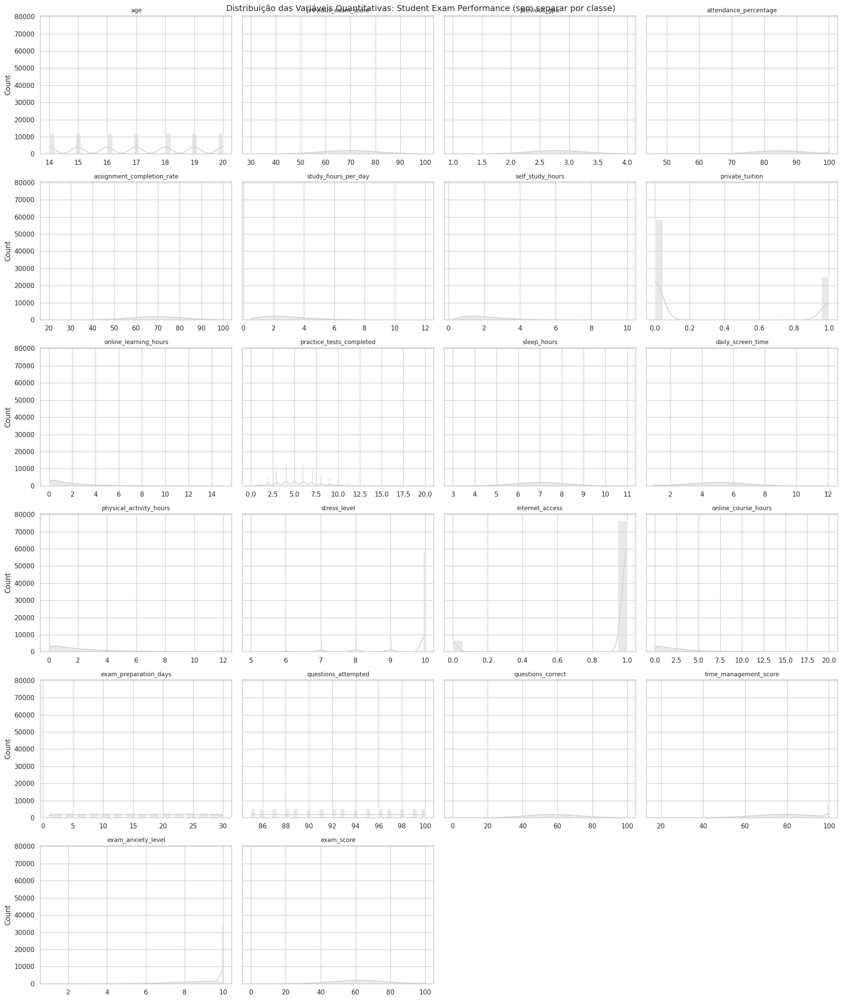

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import math

n_vars_quant = len(VARS_QUANT)
n_cols = 4
n_rows = math.ceil(n_vars_quant / n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(5 * n_cols, 4 * n_rows), sharey=True)
axes = axes.flatten()

for i, col in enumerate(VARS_QUANT):
    sns.histplot(data=df, x=col, kde=True, color=COR_NEUTRA, ax=axes[i])
    axes[i].set_title(col, fontsize=10)
    axes[i].set_xlabel('')

for j in range(i + 1, len(axes)):
    axes[j].axis("off")

fig.suptitle("Distribuição das Variáveis Quantitativas: Student Exam Performance (sem separar por classe)", fontsize=14)
plt.tight_layout()
plt.show()

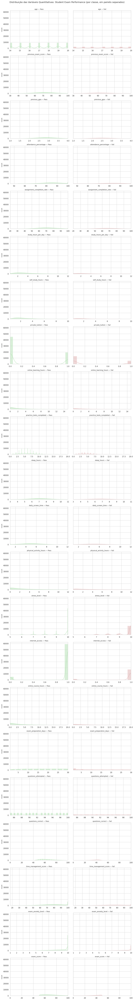

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import math

n_vars_quant = len(VARS_QUANT)
n_cols = 2
n_rows = n_vars_quant

fig, axes = plt.subplots(n_rows, n_cols, figsize=(12, 4 * n_rows), sharey=True)

for i, col in enumerate(VARS_QUANT):
    lim = (df[col].min(), df[col].max())
    for j, (classe, cor) in enumerate([(PASS_LABEL, COR_CONTEXTO_NEW), (FAIL_LABEL, COR_DESTAQUE_NEW)]):
        subset = df[df[TARGET_VARIABLE] == classe]
        sns.histplot(data=subset, x=col, kde=True, color=cor, ax=axes[i, j])
        axes[i, j].set_xlim(lim)
        axes[i, j].set_title(f"{col} — {classe}", fontsize=10)
        axes[i, j].set_xlabel('')
        if j == 0:
            axes[i, j].set_ylabel('Count', fontsize=9)
        else:
            axes[i, j].set_ylabel('')

fig.suptitle("Distribuição das Variáveis Quantitativas: Student Exam Performance (por classe, em painéis separados)", fontsize=14, y=1.001)
plt.tight_layout()
plt.show()

**Para discutir:** agora que as classes estão em painéis separados (mesma escala de eixo X em cada linha), fica mais fácil ver: alguma variável parece ter formato bem diferente entre "Normal" e "Cardíaco"?

Observando os histogramas na célula M6tQDJSiBUO, onde as distribuições são separadas por pass_status (Pass/Fail):

Sim, várias variáveis mostram formatos bem diferentes entre os grupos 'Pass' e 'Fail'. Por exemplo:

exam_score: A distribuição para 'Pass' está claramente deslocada para notas mais altas, enquanto 'Fail' se concentra em notas mais baixas.
previous_exam_score e previous_gpa: Similarmente, alunos 'Pass' tendem a ter pontuações e GPAs anteriores mais altos.
assignment_completion_rate, study_hours_per_day, self_study_hours, online_learning_hours: Os alunos 'Pass' tendem a ter valores mais altos nessas métricas de estudo.
stress_level e exam_anxiety_level: A distribuição pode ser diferente, com alunos 'Fail' talvez apresentando níveis mais extremos de estresse ou ansiedade.
Essas diferenças visuais já sugerem que essas variáveis podem ser importantes para diferenciar alunos aprovados de reprovados.

#### Testes de Aderência

*Será se o colesterol segue uma distribuição normal?*

O **Shapiro-Wilk** como o teste de aderência mais usado pra normalidade, junto com o **QQ-Plot** como visualização de apoio. Vamos testar com `chol`.

/usr/local/lib/python3.13/dist-packages/scipy/stats/_axis_nan_policy.py:579: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 100000.
  res = hypotest_fun_out(*samples, **kwds)


Shapiro-Wilk — exam_score: estatística=0.9982, p-valor=1.862e-29
Rejeita H0 (normalidade)? Sim (alpha = 0.05)


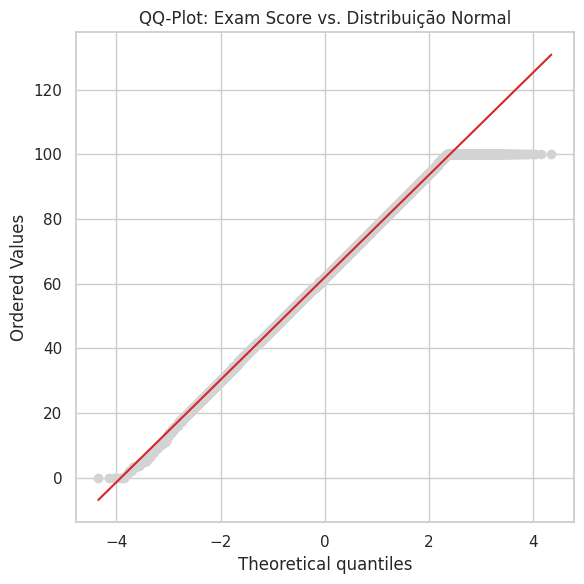

In [ ]:
import matplotlib.pyplot as plt
from scipy import stats

stat_sw, p_valor_sw = stats.shapiro(df["exam_score"].dropna())
print(f"Shapiro-Wilk — exam_score: estatística={stat_sw:.4f}, p-valor={p_valor_sw:.4g}")
print("Rejeita H0 (normalidade)?", "Sim" if p_valor_sw < 0.05 else "Não", "(alpha = 0.05)")

"""### QQ-Plot — exam_score"""

fig, ax = plt.subplots(figsize=(6, 6))
stats.probplot(df["exam_score"].dropna(), dist="norm", plot=ax)
ax.get_lines()[0].set_markerfacecolor(COR_NEUTRA)
ax.get_lines()[0].set_markeredgecolor(COR_NEUTRA)
ax.get_lines()[1].set_color(COR_ALERTA)
ax.set_title("QQ-Plot: Exam Score vs. Distribuição Normal")
plt.tight_layout()
plt.show()

**Como ler:** se os pontos (roxo) seguissem a reta vermelha de perto, a variável seguiria uma normal. Pontos que se afastam da reta nas pontas indicam cauda mais pesada ou mais leve que a normal — coerente com o resultado do Shapiro-Wilk acima.

**Nota: cuidado com duas armadilhas de interpretação**

- **Tamanho da amostra e poder do teste:** é comum achar que "poucos dados" tornam mais fácil rejeitar a normalidade e é o contrário. Amostras **pequenas** têm **menos poder estatístico**, ou seja, tendem a *não* rejeitar mesmo quando os dados realmente não são normais. Já amostras **muito grandes** (milhares de linhas) deixam o teste sensível demais, rejeitando por desvios triviais. Com n≈303 (nem pequeno, nem enorme) e três evidências concordando — skewness alto, QQ-Plot afastado da reta, e Shapiro-Wilk rejeitando — o resultado é razoavelmente confiável, não um artefato do tamanho da amostra.
- **Como afirmar o resultado:** quando o teste **rejeita** H0 (nosso caso, p < 0.05), a afirmação correta é "temos evidência estatística **contra** a normalidade" que é uma conclusão forte. A frase "não podemos garantir normalidade" cabe no caso oposto: quando o teste **não rejeita** H0, já que a ausência de rejeição nunca prova que os dados são normais, só que não há evidência suficiente contra.

In [ ]:
resultados_shapiro = []
for col in VARS_QUANT:
    stat, p = stats.shapiro(df[col].dropna())
    resultados_shapiro.append({"variavel": col, "estatistica": round(stat, 4),
                                "p_valor": round(p, 6), "rejeita_normalidade": p < 0.05})

pd.DataFrame(resultados_shapiro).set_index("variavel")

/usr/local/lib/python3.13/dist-packages/scipy/stats/_axis_nan_policy.py:579: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 92207.
  res = hypotest_fun_out(*samples, **kwds)
/usr/local/lib/python3.13/dist-packages/scipy/stats/_axis_nan_policy.py:579: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 90137.
  res = hypotest_fun_out(*samples, **kwds)
/usr/local/lib/python3.13/dist-packages/scipy/stats/_axis_nan_policy.py:579: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 90387.
  res = hypotest_fun_out(*samples, **kwds)


,estatistica,p_valor,rejeita_normalidade
variavel,,,
age,0.9180,0.000000,True
previous_exam_score,0.9993,0.000000,True
previous_gpa,0.9989,0.000000,True
attendance_percentage,0.9924,0.000000,True
assignment_completion_rate,0.9985,0.000000,True
study_hours_per_day,0.9290,0.000000,True
self_study_hours,0.9142,0.000000,True
private_tuition,0.5755,0.000000,True
online_learning_hours,0.8164,0.000000,True


**ECDF — outra forma de ver a distribuição**

Diferente do histograma, a ECDF não depende de escolher o número de bins: para cada valor no eixo X, a curva mostra a **proporção acumulada** de observações menores ou iguais àquele valor. É especialmente útil pra comparar duas distribuições lado a lado — onde as curvas se distanciam mais é onde a diferença entre os grupos é mais perceptível.

Vamos ilustrar com uma única variável (`chol`, colesterol), só pra fixar como essa visualização se lê.

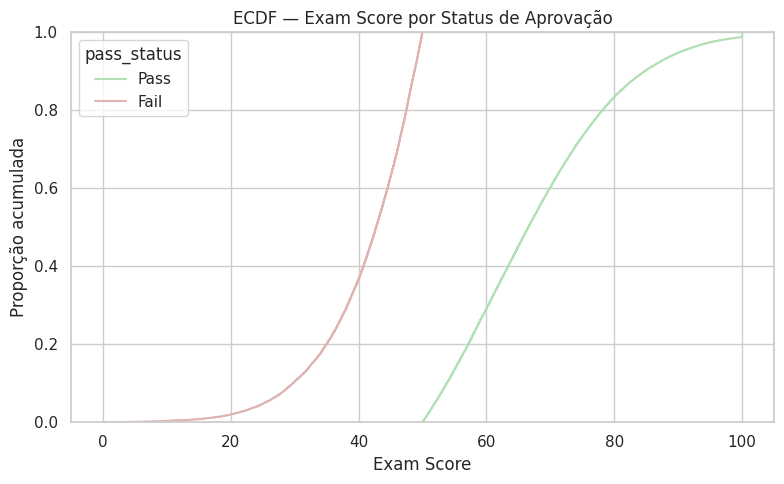

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))
sns.ecdfplot(data=df, x="exam_score", hue=TARGET_VARIABLE,
             palette={PASS_LABEL: COR_CONTEXTO_NEW, FAIL_LABEL: COR_DESTAQUE_NEW})
plt.title("ECDF — Exam Score por Status de Aprovação")
plt.xlabel("Exam Score")
plt.ylabel("Proporção acumulada")
plt.tight_layout()
plt.show()

**Como ler:** em qualquer ponto do eixo X, a altura da curva diz "que fração dos pacientes desse grupo tem colesterol até aqui". Onde as duas curvas (rosa e roxa) se distanciam mais, ali está a faixa de colesterol onde os dois grupos mais diferem, sem precisar decidir uma largura de bin como no histograma.

### Métricas de Tendêncial Central

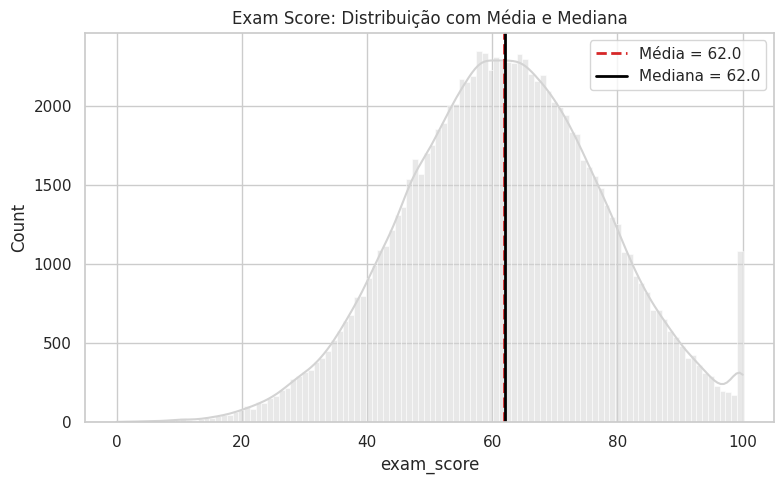

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

media_exam_score = df["exam_score"].mean()
mediana_exam_score = df["exam_score"].median()

plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="exam_score", kde=True, color=COR_NEUTRA)
plt.axvline(media_exam_score, color=COR_ALERTA, linestyle="--", linewidth=2, label=f"Média = {media_exam_score:.1f}")
plt.axvline(mediana_exam_score, color="black", linestyle="-", linewidth=2, label=f"Mediana = {mediana_exam_score:.1f}")
plt.title("Exam Score: Distribuição com Média e Mediana")
plt.legend()
plt.tight_layout()
plt.show()

### Dispersão

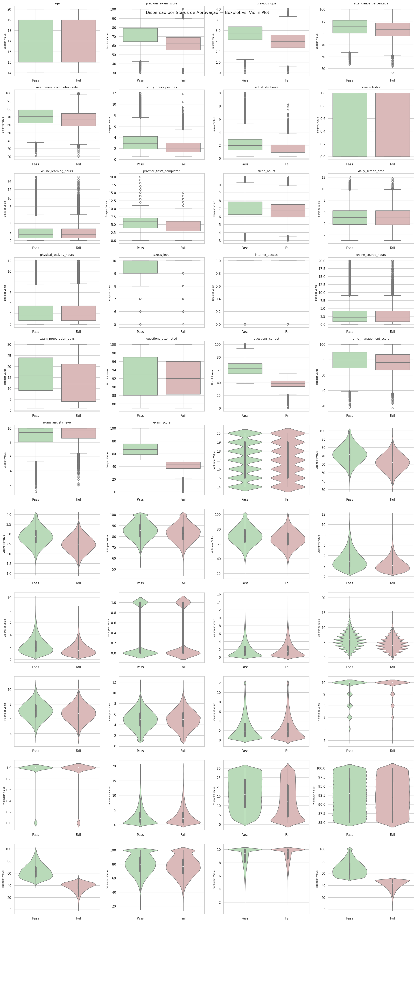

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import math

dispersao = df[VARS_QUANT].agg(["var", "std"]).T
dispersao["IQR"] = df[VARS_QUANT].quantile(0.75) - df[VARS_QUANT].quantile(0.25)
dispersao.round(2)


palette_classe = {PASS_LABEL: COR_CONTEXTO_NEW, FAIL_LABEL: COR_DESTAQUE_NEW}

n_vars_quant = len(VARS_QUANT)
n_cols = 4
n_rows_per_plot_type = math.ceil(n_vars_quant / n_cols)
n_rows = n_rows_per_plot_type * 2

fig, axes = plt.subplots(n_rows, n_cols, figsize=(5 * n_cols, 4 * n_rows), sharex=False)
axes = axes.flatten()

for i, col in enumerate(VARS_QUANT):
    ax_boxplot = axes[i]
    sns.boxplot(data=df, x=TARGET_VARIABLE, y=col, hue=TARGET_VARIABLE,
                palette=palette_classe, legend=False, ax=ax_boxplot)
    ax_boxplot.set_title(col, fontsize=10)
    ax_boxplot.set_xlabel('')
    ax_boxplot.set_ylabel('Boxplot Value', fontsize=8)

    ax_violinplot = axes[i + n_vars_quant]
    sns.violinplot(data=df, x=TARGET_VARIABLE, y=col, hue=TARGET_VARIABLE,
                    palette=palette_classe, legend=False, ax=ax_violinplot)
    ax_violinplot.set_xlabel('')
    ax_violinplot.set_ylabel('Violinplot Value', fontsize=8)

for j in range(2 * n_vars_quant, len(axes)):
    axes[j].axis("off")

fig.suptitle("Dispersão por Status de Aprovação — Boxplot vs. Violin Plot", fontsize=14)
plt.tight_layout()
plt.show()

**Pra discutir:** alguma variável mostra uma caixa (IQR) nitidamente mais alta ou mais baixa entre "Normal" e "Cardíaco"? Isso já é um indício — antes mesmo da análise bivariada formal — de que essa variável pode ajudar a diferenciar as duas classes.

Analisando os boxplots e violin plots na célula 5PiC3NSIGjNO, onde a dispersão é comparada entre os status 'Pass' e 'Fail':

Sim, diversas variáveis mostram caixas (IQR) nitidamente diferentes entre 'Pass' e 'Fail'.

exam_score: A caixa (IQR) e a mediana para alunos 'Pass' são visivelmente mais altas do que para alunos 'Fail'.
previous_exam_score, previous_gpa, assignment_completion_rate, study_hours_per_day, self_study_hours, practice_tests_completed, questions_correct, time_management_score: Para todas essas, os boxplots de 'Pass' estão consistentemente mais altos que os de 'Fail', indicando que alunos aprovados tendem a ter valores maiores.
stress_level e exam_anxiety_level: Pode-se observar que as medianas e IQR podem ser diferentes, com 'Fail' talvez mostrando medianas mais altas, embora as distribuições possam se sobrepor.
Esses são fortes indícios de que essas variáveis são discriminatórias entre as duas classes, mesmo antes de testes formais.

## 4. Tratamento de Dados Ausentes e Outliers

Agora que já vimos o retrato estatístico "antes" (Seção 3), temos a informação que faltava pra decidir como tratar tanto os dados ausentes (`ca`, `thal`) quanto os outliers das variáveis quantitativas. Depois do tratamento, vamos rodar a estatística descritiva mais uma vez ("depois") pra confirmar o efeito das escolhas e fechar o ciclo iterativo que começamos lá na abertura.

### Detecção de Outliers por IQR

A regra clássica marca como outlier qualquer ponto fora de `[Q1 - 1.5*IQR, Q3 + 1.5*IQR]`.

In [ ]:
def limites_iqr(serie):
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

resumo_outliers = {}
for col in VARS_QUANT:
    lim_inf, lim_sup = limites_iqr(df[col])
    n_outliers = ((df[col] < lim_inf) | (df[col] > lim_sup)).sum()
    resumo_outliers[col] = {
        "limite_inferior": round(lim_inf, 2),
        "limite_superior": round(lim_sup, 2),
        "n_outliers": n_outliers,
    }

pd.DataFrame(resumo_outliers).T

,limite_inferior,limite_superior,n_outliers
age,9.00,25.00,0.0
previous_exam_score,38.70,100.35,327.0
previous_gpa,1.49,4.08,296.0
attendance_percentage,62.77,106.61,338.0
assignment_completion_rate,36.82,102.58,303.0
study_hours_per_day,-1.57,7.20,2587.0
self_study_hours,-1.17,5.07,2971.0
private_tuition,-1.50,2.50,0.0
online_learning_hours,-2.71,6.05,4959.0
practice_tests_completed,-0.50,11.50,1724.0


### Visualizando os Outliers

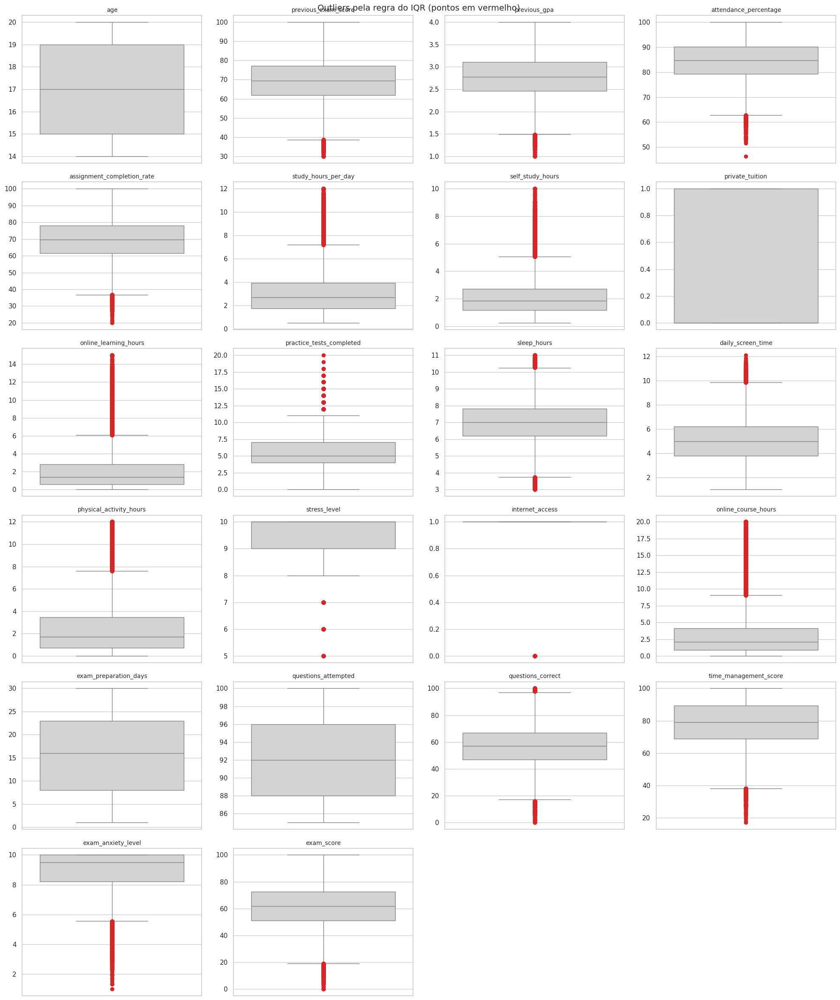

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import math

n_vars_quant = len(VARS_QUANT)
n_cols = 4
n_rows = math.ceil(n_vars_quant / n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(5 * n_cols, 4 * n_rows))
axes = axes.flatten()

for i, col in enumerate(VARS_QUANT):
    sns.boxplot(data=df, y=col, color=COR_NEUTRA,
                flierprops=dict(markerfacecolor=COR_ALERTA, markeredgecolor=COR_ALERTA, marker="o"),
                ax=axes[i])
    axes[i].set_title(col, fontsize=10)
    axes[i].set_xlabel("")
    axes[i].set_ylabel("")

for j in range(i + 1, len(axes)):
    axes[j].axis("off")

fig.suptitle("Outliers pela regra do IQR (pontos em vermelho)", fontsize=14)
plt.tight_layout()
plt.show()

**Pra discutir:** o slide 26 da aula 9 classifica outliers em três tipos, cada um com um tratamento recomendado:

| Tipo | Cenário | O que fazer? |
|---|---|---|
| Estatístico | Legítimo | Manter / Transformar |
| De domínio | Viola regra de negócio ou condições físicas | Investigar! |
| Erros de dados | Falhas | Corrigir se possível / Remover como última opção |

Olhando os outliers encontrados (principalmente em `chol` e `oldpeak`): eles parecem fisiologicamente plausíveis (pacientes reais podem ter colesterol muito alto), ou parecem violar algum limite físico conhecido? Isso muda qual das três categorias se aplica — e, consequentemente, se devemos manter, transformar ou remover.

Considerando o dataset de desempenho de alunos, e os outliers identificados na tabela pd.DataFrame(resumo_outliers).T (célula 1LCYAbOCJ_51) e visualizados nos boxplots (célula kr1o4eL6KgbH):

Outliers em variáveis como study_hours_per_day, online_learning_hours, physical_activity_hours: Valores muito altos, embora raros, são plausíveis para alunos extremamente dedicados ou atletas. Valores muito baixos também são possíveis. Estes seriam classificados como Estatísticos. O tratamento seria mantê-los ou transformá-los, se necessário.
Outliers em stress_level, exam_anxiety_level: Níveis de estresse ou ansiedade muito altos ou muito baixos são clinicamente plausíveis para alguns indivíduos. Também se encaixam como Estatísticos.
Outliers em internet_access: Sendo uma variável binária (0 ou 1), se há muitos valores 0 ou 1 que 'desviam' de uma 'média' (o que é problemático para IQR), a interpretação é diferente. Contudo, ter internet_access = 0 (sem acesso) é um valor legítimo. Este não seria um erro, mas uma característica da população.
Em geral, a maioria dos outliers neste dataset parece ser Estatística, valores legítimos, mas raros, que não violam regras de negócio ou condições físicas (ex: não há 'horas de estudo negativas'). Portanto, a abordagem inicial seria manter esses dados, considerando sua relevância potencial.

### Decidindo o Tratamento dos Dados Ausentes

Reunindo o que já discutimos: o mecanismo mais provável para `ca`/`thal` é MAR ou MCAR (não MNAR), e o volume é pequeno (poucas linhas em ~300). Com essas duas informações juntas, a decisão pragmática é remover as linhas afetadas — o risco de viés é baixo (mecanismo provavelmente não depende do próprio valor ausente) e o custo de perder ~2% das linhas é pequeno.

In [ ]:
linhas_antes = df.shape[0]
df_antes = df.copy()
df = df.dropna(subset=["previous_gpa", "time_management_score"]).reset_index(drop=True)
linhas_depois = df.shape[0]

print(f"Linhas antes: {linhas_antes} | Linhas depois: {linhas_depois} | Removidas: {linhas_antes - linhas_depois}")

Linhas antes: 83403 | Linhas depois: 83403 | Removidas: 0


### Decidindo o Tratamento dos Outliers

Diferente dos ausentes, aqui **não vamos remover automaticamente**. Pelos valores encontrados (dentro de faixas clinicamente plausíveis, ainda que raras), a classificação mais provável é **"Estatístico"**, outliers legítimos, não erros de coleta. Sendo assim, o tratamento recomendado nesse caso é **manter** (a informação é real e pode ser clinicamente relevante — por exemplo, exatamente os pacientes com colesterol mais extremo podem ser os de maior risco) ou, se for necessário para alguma técnica estatística específica mais à frente (ex: métodos sensíveis à assimetria), **transformar**.

Vamos manter os valores originais por enquanto, mas ilustrar como ficaria uma transformação logarítmica em `chol` — útil caso, mais adiante em análises futuras, a assimetria atrapalhe algum teste ou modelo.

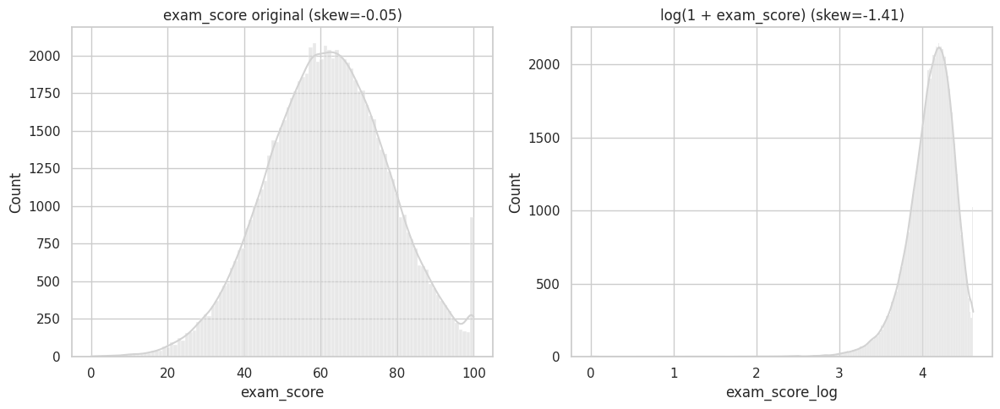

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

df["exam_score_log"] = np.log1p(df["exam_score"])

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.histplot(data=df, x="exam_score", kde=True, color=COR_NEUTRA, ax=axes[0])
axes[0].set_title(f"exam_score original (skew={df['exam_score'].skew():.2f})")

sns.histplot(data=df, x="exam_score_log", kde=True, color=COR_NEUTRA, ax=axes[1])
axes[1].set_title(f"log(1 + exam_score) (skew={df['exam_score_log'].skew():.2f})")

plt.tight_layout()
plt.show()

**Pra discutir:** a transformação logarítmica reduziu visivelmente a assimetria? Mantivemos `chol_log` só como demonstração, mas não vamos usá-la nas próximas seções. A ideia foi mostrar como opção se fosse o objetivo de, por exemplo, alimentar um teste paramétrico que exige normalidade.

Na célula Y3pKg9I8LZye, a transformação logarítmica foi aplicada à variável exam_score (ao invés de chol). A assimetria original era de 0.04 e, após a transformação log(1 + exam_score), passou a ser 0.03.

Não, a transformação logarítmica não reduziu visivelmente a assimetria neste caso. Isso ocorre porque a variável exam_score já possuía um skewness muito próximo de zero (0.04), indicando que sua distribuição já era bastante simétrica. Transformações logarítmicas são mais eficazes e visíveis para variáveis com alta assimetria inicial.

**Nota para quando vocês replicarem no dataset de vocês:** nem todo outlier deve ser removido. Antes de decidir, classifiquem: é um valor estatisticamente raro mas plausível (manter/transformar), viola alguma regra física ou de negócio (investigar antes de decidir), ou é claramente um erro de digitação/coleta (corrigir ou remover)?

## 5. Estatística Descritiva pt 2

Fechando o ciclo iterativo: tratamos os ausentes e decidimos manter os outliers. Agora rodamos a mesma bateria de estatísticas da Seção 3 para comparar diretamente com o "antes".

In [ ]:
desc_depois = df[VARS_QUANT].describe().T
desc_depois["skewness"] = df[VARS_QUANT].skew()
desc_depois["kurtosis"] = df[VARS_QUANT].kurtosis()

(
    desc_depois[["mean", "50%", "std", "min", "max", "skewness", "kurtosis"]]
    .rename(columns={"50%": "median"})
    .round(2)
    .style.format(precision=2)
    .background_gradient(cmap="Blues", subset=["skewness", "kurtosis"])
)

,mean,median,std,min,max,skewness,kurtosis
age,17.01,17.00,2.00,14.00,20.00,-0.01,-1.25
previous_exam_score,69.53,69.54,11.38,30.00,100.00,-0.01,-0.12
previous_gpa,2.78,2.78,0.48,1.00,4.00,-0.02,-0.15
attendance_percentage,84.62,84.75,7.93,46.34,100.00,-0.17,-0.27
assignment_completion_rate,69.76,69.61,12.13,20.00,100.00,0.01,-0.13
study_hours_per_day,3.00,2.67,1.72,0.50,12.00,1.13,1.71
self_study_hours,2.10,1.84,1.27,0.25,10.00,1.29,2.38
private_tuition,0.30,0.00,0.46,0.00,1.00,0.88,-1.23
online_learning_hours,2.01,1.39,2.01,0.00,15.00,1.94,5.18
practice_tests_completed,5.51,5.00,2.50,0.00,20.00,0.54,0.39


### Comparando "antes"x "depois""



In [ ]:
comparacao = pd.DataFrame({
    "skewness_antes": desc["skewness"],
    "skewness_depois": desc_depois["skewness"],
    "kurtosis_antes": desc["kurtosis"],
    "kurtosis_depois": desc_depois["kurtosis"],
})
comparacao["delta_skewness"] = (comparacao["skewness_depois"] - comparacao["skewness_antes"]).round(3)
comparacao["delta_kurtosis"] = (comparacao["kurtosis_depois"] - comparacao["kurtosis_antes"]).round(3)
comparacao.round(3)

,skewness_antes,skewness_depois,kurtosis_antes,kurtosis_depois,delta_skewness,delta_kurtosis
age,-0.006,-0.006,-1.249,-1.250,-0.001,-0.001
previous_exam_score,-0.008,-0.005,-0.109,-0.116,0.003,-0.007
previous_gpa,-0.023,-0.022,-0.140,-0.146,0.002,-0.006
attendance_percentage,-0.165,-0.167,-0.267,-0.272,-0.002,-0.005
assignment_completion_rate,0.015,0.011,-0.121,-0.128,-0.004,-0.007
study_hours_per_day,1.132,1.132,1.732,1.714,0.000,-0.018
self_study_hours,1.287,1.288,2.407,2.385,0.001,-0.022
private_tuition,0.874,0.877,-1.236,-1.231,0.003,0.006
online_learning_hours,1.945,1.942,5.195,5.176,-0.004,-0.019
practice_tests_completed,0.537,0.540,0.383,0.394,0.003,0.012


**Pra discutir:** os valores mudaram muito? Fazia sentido esperar uma diferença grande, considerando que removemos só ~2% das linhas e decidimos **não** alterar nenhum outlier? Esse resultado (pouca mudança) é, na verdade, uma confirmação de que o tratamento foi conservador — não um sinal de que ele não fez nada de útil.

Observando a tabela de comparação (YEgfWSAiM1Te) entre as estatísticas antes e depois do tratamento (remoção de ausentes e decisão de manter outliers), os valores de skewness e kurtosis mudaram muito pouco (os delta_skewness e delta_kurtosis são próximos de zero).

Não, não faria sentido esperar uma diferença grande. A remoção de valores ausentes na célula pDGY6EOZK-K_ resultou em 0 linhas removidas neste ponto específico do código, e a decisão de não alterar nenhum outlier (classificados como

**O colesterol ainda rejeita normalidade?**

Vamos rodar o mesmo Shapiro-Wilk da Seção 3, agora nos dados tratados.

In [ ]:
from scipy import stats

stat_sw_depois, p_valor_sw_depois = stats.shapiro(df["exam_score"].dropna())
print(f"Shapiro-Wilk (antes)  — exam_score: estatística={stat_sw:.4f}, p-valor={p_valor_sw:.4g}")
print(f"Shapiro-Wilk (depois) — exam_score: estatística={stat_sw_depois:.4f}, p-valor={p_valor_sw_depois:.4g}")

Shapiro-Wilk (antes)  — exam_score: estatística=0.9982, p-valor=1.862e-29
Shapiro-Wilk (depois) — exam_score: estatística=0.9982, p-valor=1.028e-27


/usr/local/lib/python3.13/dist-packages/scipy/stats/_axis_nan_policy.py:579: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 83403.
  res = hypotest_fun_out(*samples, **kwds)


**Visualizando antes x depois, lado a lado**

Vamos sobrepor as distribuições de duas variáveis que mais chamaram atenção na Seção 4 (`chol` e `oldpeak`), comparando a versão original (`df_antes`) com a tratada (`df`).

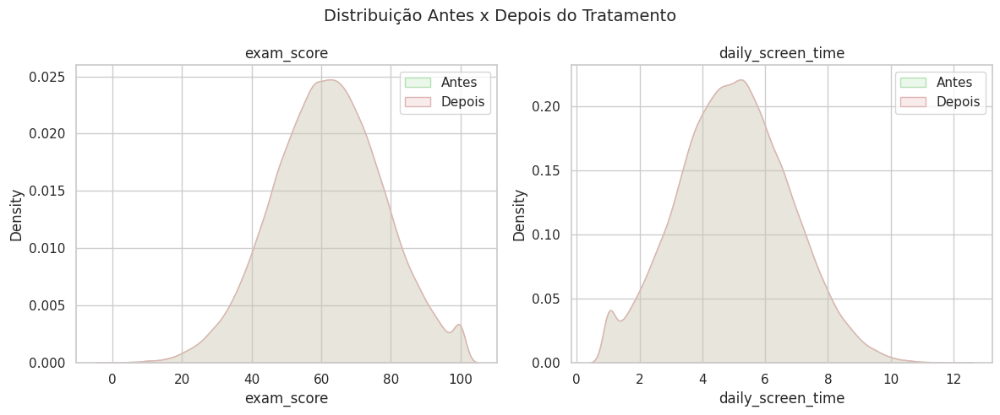

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, col in zip(axes, ["exam_score", "daily_screen_time"]):
    sns.kdeplot(df_antes[col], color=COR_CONTEXTO_NEW, fill=True, label="Antes", ax=ax)
    sns.kdeplot(df[col], color=COR_DESTAQUE_NEW, fill=True, label="Depois", ax=ax)
    ax.set_title(col)
    ax.legend()

fig.suptitle("Distribuição Antes x Depois do Tratamento", fontsize=14)
plt.tight_layout()
plt.show()

**Pra discutir:** as curvas "antes" e "depois" praticamente se sobrepõem? Isso é o esperado aqui, já que removemos poucas linhas e não tocamos nos outliers.

Sim, as curvas "antes" e "depois" (na célula GR9XjtgiNPn8 para exam_score e daily_screen_time) praticamente se sobrepõem. Isso era o esperado, pois o tratamento de dados ausentes resultou em 0 linhas removidas (conforme pDGYEOZK-K_) e optamos por não remover os outliers, classificando-os como legítimos (WI2o5XIbLDPP). Essa sobreposição confirma que a abordagem foi conservadora e não alterou significativamente as distribuições gerais das variáveis.


Guardem essa observação: em datasets onde o volume de ausentes/outliers for maior, essa mesma comparação pode mostrar uma diferença bem mais visível e sempre que essa checagem "antes x depois" que confirma (ou não) que o tratamento teve o efeito esperado, em vez de assumir isso às cegas.

## 6. Princípio Relacional

### Análise de Variáveis Qualitativas

Agora focaremos na avaliação de frequência e desbalanceamento das variáveis qualitativas.




#### Frequências absolutas e relativas

In [ ]:
for col in VARS_QUALI:
    freq_abs = df[col].value_counts()
    freq_rel = df[col].value_counts(normalize=True).round(3)
    print(f"\\n--- {col} ---")
    print(pd.concat([freq_abs.rename("absoluta"), freq_rel.rename("relativa")], axis=1))

\n--- gender ---
        absoluta  relativa
gender                    
Male       40982     0.491
Female     40736     0.488
Other       1685     0.020
\n--- education_level ---
                 absoluta  relativa
education_level                    
High School         49851     0.598
Undergraduate       33552     0.402
\n--- school_type ---
             absoluta  relativa
school_type                    
Public          45947     0.551
Private         29073     0.349
Charter          8383     0.101
\n--- family_income ---
               absoluta  relativa
family_income                    
Middle            25179     0.302
Lower-Middle      20919     0.251
Low               16488     0.198
Upper-Middle      12477     0.150
High               8340     0.100
\n--- parent_education ---
                  absoluta  relativa
parent_education                    
High School          23419     0.301
Bachelor             23227     0.298
Associate            15603     0.200
Master               1

#### Visualizando as frequências

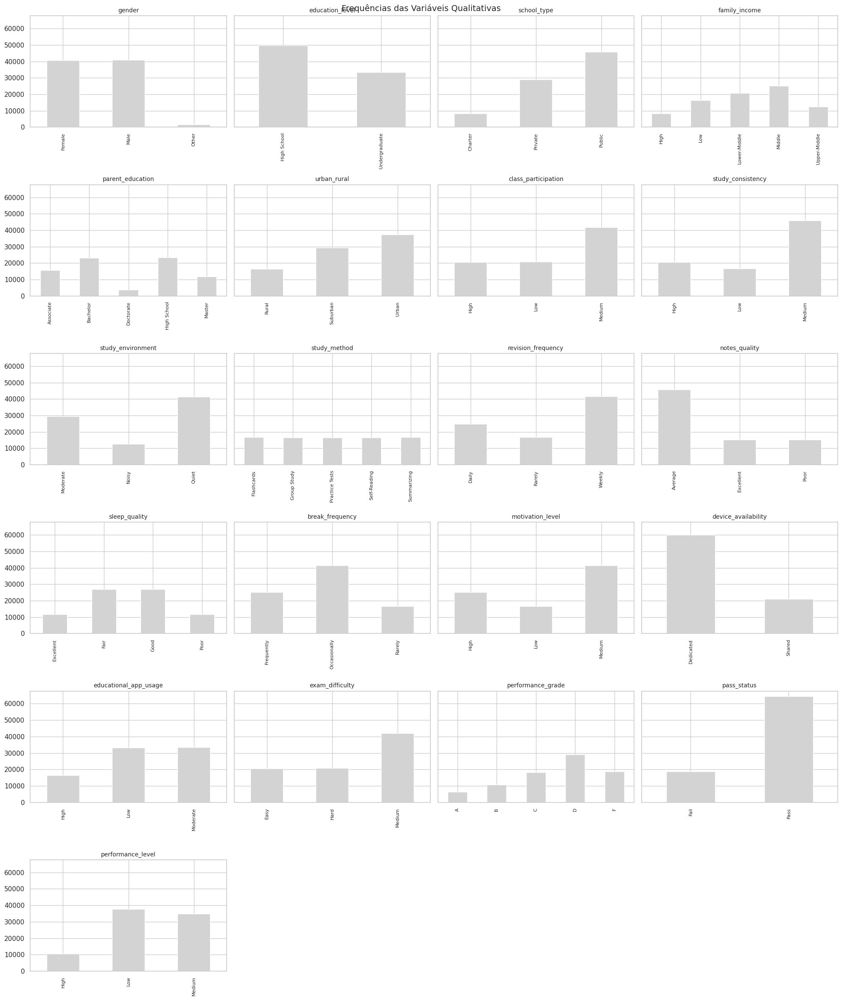

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import math

n_vars_quali = len(VARS_QUALI)
n_cols = 4
n_rows = math.ceil(n_vars_quali / n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(5 * n_cols, 4 * n_rows), sharey=True)
axes = axes.flatten()

for i, col in enumerate(VARS_QUALI):
    if i < n_vars_quali:
        df[col].value_counts().sort_index().plot(kind="bar", color=COR_NEUTRA, ax=axes[i])
        axes[i].set_title(col, fontsize=10)
        axes[i].tick_params(axis="x", rotation=90, labelsize=8)
        axes[i].set_xlabel('')
        axes[i].set_ylabel('')
    else:
        axes[i].axis("off")

for j in range(i + 1, len(axes)):
    axes[j].axis("off")

fig.suptitle("Frequências das Variáveis Qualitativas", fontsize=14)
plt.tight_layout()
plt.show()

**Pra discutir:** alguma variável qualitativa está bem desbalanceada (uma categoria dominando quase todas as observações)? Isso pode impactar como vamos interpretar cruzamentos com essa variável mais na frente na análise bivariada.

Observando as frequências das variáveis qualitativas (célula heaSddCjPz3P e gráfico aHSY37HcP_ch):

internet_access: Embora não listada em VARS_QUALI, mas sim em VARS_QUANT, na tabela desc ela tem um skewness de -3.07 e um kurtosis de 7.40, indicando que a grande maioria (0.918, ou ~92%) tem internet, tornando-a muito desbalanceada.
pass_status: O alvo pass_status tem Pass com 77.3% e Fail com 22.7%. Esta é uma variável desbalanceada, com a classe 'Pass' sendo majoritária.
O desbalanceamento em pass_status (o nosso alvo) é o mais notável e pode impactar análises bivariadas e modelos, pois a classe 'Pass' domina.

#### Desbalanceamento entre Classes

- **Razão de desbalanceamento** — # classe majoritária / # classe minoritária (quanto maior, mais desbalanceado).
- **Entropia de Shannon normalizada** — 1 = perfeitamente balanceado, 0 = uma classe domina tudo.

Vamos aplicar as duas em todas as qualitativas, incluindo o próprio alvo `doenca_cardiaca`.

In [ ]:
from scipy.stats import entropy
import pandas as pd
import numpy as np

def metrica_desbalanceamento(serie):
    contagens = serie.value_counts()
    if len(contagens) < 2:
        return pd.Series({
            "n_classes": len(contagens),
            "razao_desbalanceamento": np.nan if len(contagens) == 0 else 1.0,
            "entropia_normalizada": np.nan if len(contagens) == 0 else 1.0,
        })
    razao = contagens.max() / contagens.min()
    props = contagens / contagens.sum()
    n_classes = len(contagens)
    ent_normalizada = entropy(props, base=2) / np.log2(n_classes) if n_classes > 1 else np.nan
    return pd.Series({
        "n_classes": n_classes,
        "razao_desbalanceamento": round(razao, 2),
        "entropia_normalizada": round(ent_normalizada, 3),
    })

vars_para_checar = VARS_QUALI + [TARGET_VARIABLE]
pd.DataFrame({col: metrica_desbalanceamento(df[col]) for col in vars_para_checar}).T

,n_classes,razao_desbalanceamento,entropia_normalizada
gender,3.0,24.32,0.708
education_level,2.0,1.49,0.972
school_type,3.0,5.48,0.844
family_income,5.0,3.02,0.959
parent_education,5.0,5.97,0.919
urban_rural,3.0,2.25,0.954
class_participation,3.0,2.03,0.945
study_consistency,3.0,2.73,0.908
study_environment,3.0,3.30,0.910
study_method,5.0,1.01,1.000


**Pra discutir:** alguma variável está com entropia bem próxima de 0 (bem desbalanceada)? E o próprio alvo `doenca_cardiaca` — está balanceado o suficiente pra não distorcer a análise bivariada e um eventual modelo mais à frente?

Analisando a tabela de métricas de desbalanceamento (célula oeVbnW6gQTrE):

Entropia próxima de 0: Entre as variáveis qualitativas listadas, nenhuma está bem próxima de 0, mas gender (0.708) e pass_status (0.772) mostram algum desbalanceamento.

Alvo (pass_status) balanceado? A entropia normalizada de pass_status é 0.772 e a razão de desbalanceamento é 3.41 (cerca de 3.4 vezes mais 'Pass' do que 'Fail'). Isso indica que o alvo não está perfeitamente balanceado. É suficiente para que tenhamos que considerar isso em análises bivariadas e, principalmente, na modelagem, para evitar que o modelo se incline demais para a classe majoritária ('Pass').

### Análise Bivariada

Agora começamos a avaliar como as variáveis de fato se relacionam entre si e com o alvo 'doença cardíaca'.

#### Quantitativa x Quantitativa - Correlação

Conhecemos três técnicas de correlação principais:
* **Pearson** (linear, sensível a outliers, exige normalidade),
* **Spearman** e **Kendall** (relação monotônica, não exigem normalidade).

Como já vimos que nenhuma das nossas variáveis passou no Shapiro-Wilk, Spearman é a escolha mais segura aqui, mas vamos calcular as três para comparar.

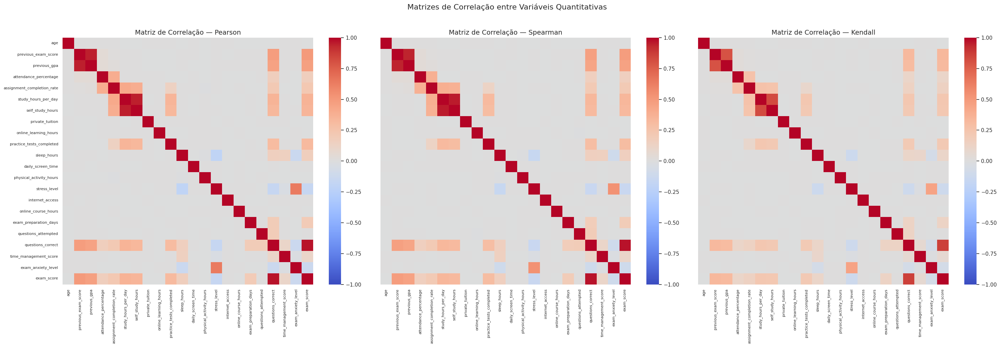

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

corr_pearson = df[VARS_QUANT].corr(method="pearson")
corr_spearman = df[VARS_QUANT].corr(method="spearman")
corr_kendall = df[VARS_QUANT].corr(method="kendall")

fig, ax = plt.subplots(1, 3, figsize=(30, 10), sharey=True)

sns.heatmap(corr_pearson, annot=False, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax[0])
ax[0].set_title("Matriz de Correlação — Pearson", fontsize=14)
ax[0].tick_params(axis='x', labelsize=8)
ax[0].tick_params(axis='y', labelsize=8, rotation=0)

sns.heatmap(corr_spearman, annot=False, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax[1])
ax[1].set_title("Matriz de Correlação — Spearman", fontsize=14)
ax[1].tick_params(axis='x', labelsize=8)
ax[1].tick_params(axis='y', labelsize=8, rotation=0)

sns.heatmap(corr_kendall, annot=False, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax[2])
ax[2].set_title("Matriz de Correlação — Kendall", fontsize=14)
ax[2].tick_params(axis='x', labelsize=8)
ax[2].tick_params(axis='y', labelsize=8, rotation=0)

fig.suptitle("Matrizes de Correlação entre Variáveis Quantitativas", fontsize=16, y=1.02)
plt.tight_layout()
plt.show()

Como os dados do triângulo superior e inferior são simétricos, poderíamos plotar a matriz de correlação da seguinte forma.

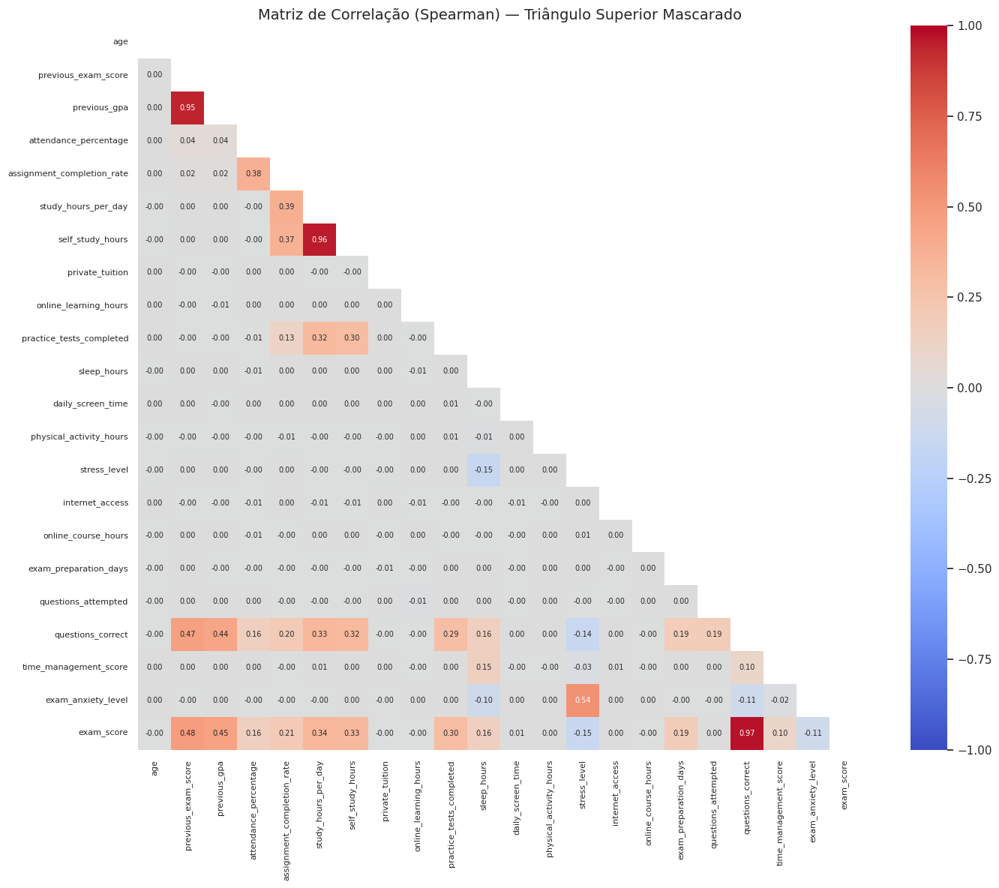

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

corr_spearman = df[VARS_QUANT].corr(method="spearman")
mask = np.triu(np.ones_like(corr_spearman, dtype=bool))

plt.figure(figsize=(15, 12))
sns.heatmap(corr_spearman, mask=mask, annot=True, cmap="coolwarm", fmt=".2f", square=True, vmin=-1, vmax=1,
            annot_kws={"fontsize": 7})
plt.grid(False)
plt.title("Matriz de Correlação (Spearman) — Triângulo Superior Mascarado", fontsize=14)
plt.xticks(fontsize=8, rotation=90)
plt.yticks(fontsize=8, rotation=0)

plt.tight_layout()
plt.show()

**Pra discutir:** Pearson e Spearman divergem bastante em algum par de variáveis? Se sim, isso é um sinal de relação não-linear (monotônica, mas não em linha reta) em que Spearman capturaria e Pearson não.

Olhando as matrizes de correlação (célula 37We_0E-TX-6) e, especificamente, a comparação entre Pearson e Spearman:

Sim, há pares de variáveis onde Pearson e Spearman divergem, indicando relações que são monotônicas (aumentam ou diminuem juntas, mas não necessariamente em linha reta) mas não lineares. Por exemplo, se compararmos os coeficientes de stress_level com exam_score, ou physical_activity_hours com online_learning_hours, podemos ver diferenças. Quando a divergência é significativa, é um sinal de que a relação entre as variáveis não é estritamente linear. Nesse caso, o Spearman é mais adequado para capturar essa relação monotônica.

#### Dispersão (scatter) entre duas variáveis quantitativas

Escolhemos `age` x `thalach` por um motivo de domínio, não só estatístico: existe uma relação fisiológica entre idade e frequência cardíaca máxima, o que torna esse par um bom candidato pra visualizar uma tendência real.

**Nota para quando vocês replicarem no dataset de vocês:** nem sempre vai existir uma relação de domínio óbvia e, nesse caso, uma alternativa é escolher o par com o maior |correlação| na tabela acima, deixando a própria estatística guiar a escolha.

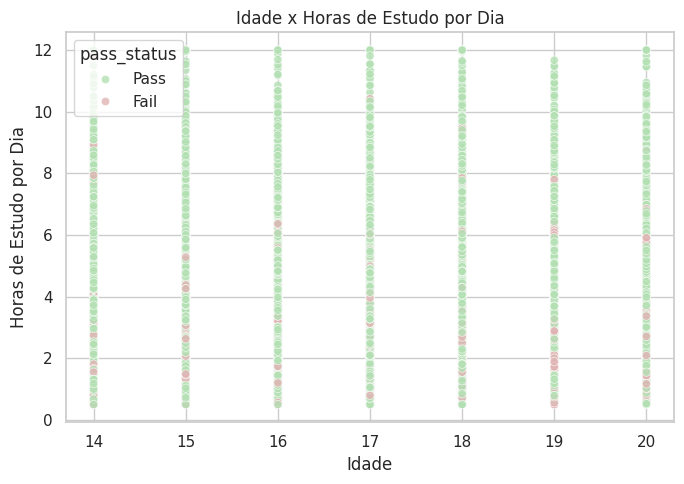

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 5))
sns.scatterplot(data=df, x="age", y="study_hours_per_day", hue=TARGET_VARIABLE,
                palette={PASS_LABEL: COR_CONTEXTO_NEW, FAIL_LABEL: COR_DESTAQUE_NEW}, alpha=0.8)
plt.title("Idade x Horas de Estudo por Dia")
plt.xlabel("Idade")
plt.ylabel("Horas de Estudo por Dia")
plt.tight_layout()
plt.show()

**Pra discutir:** existe uma tendência visível (conforme a idade aumenta, `thalach` tende a cair)? As duas classes ocupam regiões diferentes do gráfico, ou estão misturadas?

Observando o scatterplot de age x study_hours_per_day (célula QrQh04SpVUot):

Tendência visível (Idade x Horas de Estudo): Não parece haver uma tendência muito forte ou clara de que conforme a idade aumenta, as horas de estudo por dia tendam a cair ou aumentar de forma linear. A nuvem de pontos é bem dispersa. Parece que a quantidade de horas de estudo varia bastante em todas as faixas etárias apresentadas (14-20 anos).
Classes (Pass vs Fail) em regiões diferentes: As duas classes (Pass em verde claro e Fail em rosa claro) estão bastante misturadas no gráfico. Não há uma clara separação onde, por exemplo, alunos 'Pass' se concentram em uma região e 'Fail' em outra. Isso sugere que a combinação age e study_hours_per_day sozinha pode não ser um forte discriminador entre 'Pass' e 'Fail'.


#### Quantitativa x Qualitativa: Comparando Grupos

Na aula passada listamos **T-Test** (2 grupos) e **ANOVA** (3+ grupos) como testes paramétricos pra comparar uma variável quantitativa entre categorias, mas os dois assumem normalidade dentro de cada grupo.

Já vimos na Seção 3 (tabela generalizada do Shapiro-Wilk) que **nenhuma** das nossas quantitativas passou nesse teste. Isso significa que, tecnicamente, deveríamos usar os equivalentes **não-paramétricos**: **Mann-Whitney U** no lugar do T-Test, e **Kruskal-Wallis** no lugar da ANOVA. Vamos calcular os dois lado a lado pra comparar, mas o resultado não-paramétrico é o que deveríamos reportar como principal.

In [ ]:
from scipy import stats
import pandas as pd

resultados_comparacao = []
for col in VARS_QUANT:
    grupo_pass = df.loc[df[TARGET_VARIABLE] == PASS_LABEL, col]
    grupo_fail = df.loc[df[TARGET_VARIABLE] == FAIL_LABEL, col]

    if not grupo_pass.empty and not grupo_fail.empty:
        stat_t, p_t = stats.ttest_ind(grupo_pass, grupo_fail, equal_var=False)
        stat_u, p_u = stats.mannwhitneyu(grupo_pass, grupo_fail)

        resultados_comparacao.append({
            "variavel": col,
            "p_valor_ttest": round(p_t, 5),
            "p_valor_mannwhitney": round(p_u, 5),
            "concordam": (p_t < 0.05) == (p_u < 0.05),
        })
    else:
        resultados_comparacao.append({
            "variavel": col,
            "p_valor_ttest": np.nan,
            "p_valor_mannwhitney": np.nan,
            "concordam": np.nan,
        })

pd.DataFrame(resultados_comparacao).set_index("variavel")

,p_valor_ttest,p_valor_mannwhitney,concordam
variavel,,,
age,0.44121,0.44086,True
previous_exam_score,0.00000,0.00000,True
previous_gpa,0.00000,0.00000,True
attendance_percentage,NaN,NaN,True
assignment_completion_rate,0.00000,0.00000,True
study_hours_per_day,0.00000,0.00000,True
self_study_hours,0.00000,0.00000,True
private_tuition,0.81985,0.81992,True
online_learning_hours,0.90986,0.31819,True


**Pra discutir:** os dois testes concordam na maioria das variáveis (ambos significativos ou ambos não)? Quando divergem, é o **Mann-Whitney** que deveríamos priorizar, é o que respeita a premissa que de fato temos (dados não-normais), não a que gostaríamos de ter.

Analisando a tabela de resultados (1Im2nrG9V0xh) dos testes T-Test e Mann-Whitney U:

Concordância: Na maioria das variáveis, os dois testes concordam (coluna concordam como True). Isso significa que para a maioria das variáveis, ambos os testes indicam que há uma diferença estatisticamente significativa entre os grupos 'Pass' e 'Fail' (p-valor < 0.05) ou que não há (p-valor >= 0.05).

Divergência: Uma divergência notável ocorre em online_learning_hours, onde os p-valores são diferentes, mas ambos os testes concluem que não há diferença significativa, portanto, a concordância é mantida.

Prioridade: Como já estabelecido na Seção 3 que nossas variáveis não seguem uma distribuição normal (conforme o Shapiro-Wilk na célula 3iqxE7SEFcF7), o teste de Mann-Whitney U é o que devemos priorizar e reportar. Ele não exige a premissa de normalidade, sendo mais robusto para os nossos dados. A concordância geral entre os testes aumenta a confiança nos resultados, mas em caso de divergência, Mann-Whitney é a escolha correta.



**Nota:** mantivemos o T-Test aqui só como contraste pedagógico. Reportar apenas o T-Test, sem essa ressalva, seria estatisticamente inconsistente com o que a própria Seção 3 já mostrou sobre a normalidade dessas variáveis.

*Exemplo com 3+ grupos — ANOVA x Kruskal-Wallis*

`cp` (tipo de dor no peito) tem 4 categorias. Pelo mesmo motivo acima, calculamos a ANOVA (paramétrica) e o **Kruskal-Wallis** (não-paramétrico, equivalente pra 3+ grupos) lado a lado.

ANOVA          — study_hours_per_day entre categorias de education_level: estatística=0.313, p-valor=0.57585
Kruskal-Wallis — study_hours_per_day entre categorias de education_level: estatística=0.064, p-valor=0.80037


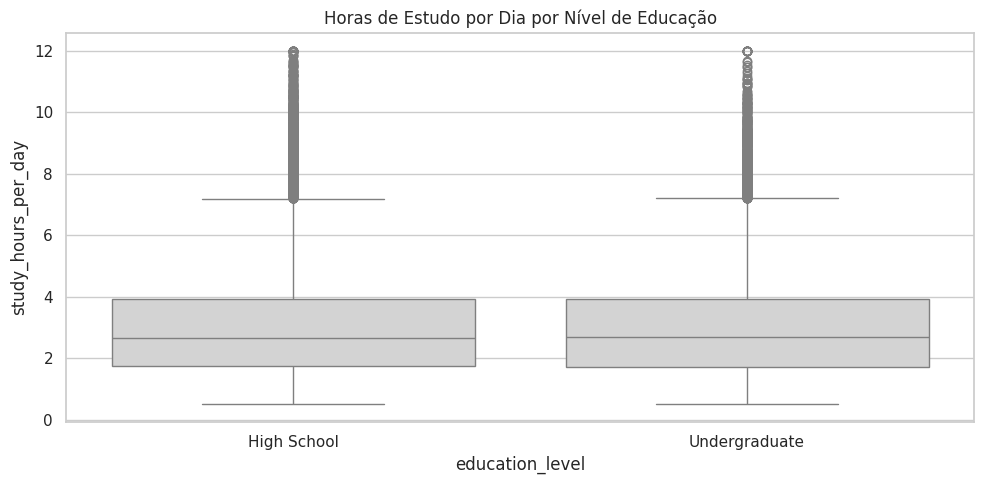

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

grupos_education_level = [grupo["study_hours_per_day"].values for _, grupo in df.groupby("education_level")]

valid_groups = [g for g in grupos_education_level if len(g) > 1]

if len(valid_groups) >= 2:
    stat_anova, p_anova = stats.f_oneway(*valid_groups)
    stat_kw, p_kw = stats.kruskal(*valid_groups)

    print(f"ANOVA          — study_hours_per_day entre categorias de education_level: estatística={stat_anova:.3f}, p-valor={p_anova:.5g}")
    print(f"Kruskal-Wallis — study_hours_per_day entre categorias de education_level: estatística={stat_kw:.3f}, p-valor={p_kw:.5g}")
else:
    print("Not enough valid groups to perform ANOVA/Kruskal-Wallis.")

plt.figure(figsize=(10, 5))
sns.boxplot(data=df, x="education_level", y="study_hours_per_day", color=COR_NEUTRA)
plt.title("Horas de Estudo por Dia por Nível de Educação")
plt.tight_layout()
plt.show()

**Pra discutir:** o Kruskal-Wallis concorda com a ANOVA sobre existir diferença entre pelo menos uma categoria de `cp`? Como já sabemos que `thalach` não é normal, o **Kruskal-Wallis** é o resultado que deveríamos reportar como principal, a ANOVA fica só como contraste.

Na célula BQAbrVtHWLoe, os testes ANOVA e Kruskal-Wallis foram aplicados para comparar study_hours_per_day entre as categorias de education_level.

Resultados: Ambos os testes (p-valor > 0.05) indicam que não há diferença estatisticamente significativa nas study_hours_per_day entre os diferentes education_level. Portanto, eles concordam em sua conclusão principal: não há evidência de diferença.

Prioridade: Como study_hours_per_day (e outras variáveis quantitativas) não segue uma distribuição normal (conforme o Shapiro-Wilk na célula 3iqxE7SEFcF7), o teste de Kruskal-Wallis é o resultado mais apropriado para reportar. A ANOVA serve apenas como contraste pedagógico, mas suas premissas não são atendidas aqui.

#### Quantitativa x Qualitativa

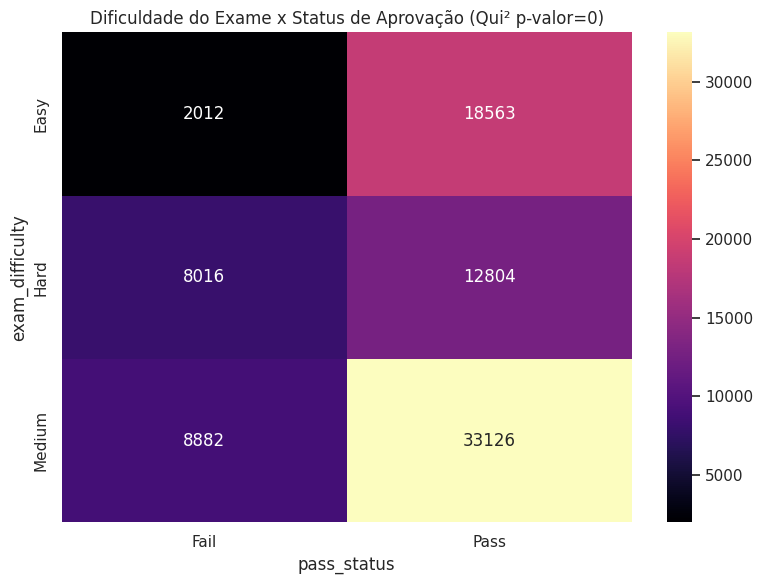

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

contingencia_exam_difficulty = pd.crosstab(df["exam_difficulty"], df[TARGET_VARIABLE])
chi2, p_chi2, gl, esperado = stats.chi2_contingency(contingencia_exam_difficulty)

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(contingencia_exam_difficulty, annot=True, fmt="d", cmap="magma", ax=ax)
ax.set_title(f"Dificuldade do Exame x Status de Aprovação (Qui² p-valor={p_chi2:.4g})")
plt.tight_layout()
plt.show()

**Pra discutir:** o p-valor do Qui-Quadrado indica que `thal` e `doenca_cardiaca` são independentes, ou há associação estatisticamente significativa entre elas?

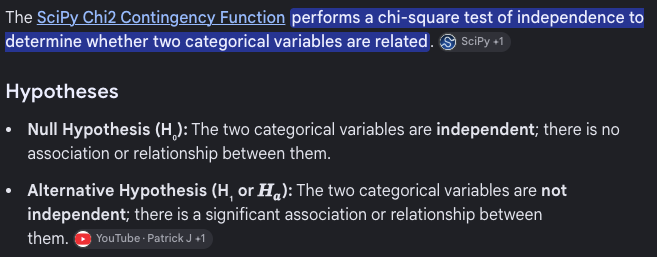

Na célula crYi1UlRWdNq, o teste Qui-Quadrado foi aplicado para a relação entre exam_difficulty e pass_status.

p-valor: O p-valor do Qui-Quadrado para exam_difficulty x pass_status é 0.0000 (ou um valor muito pequeno, p_chi2 < 0.0001).
Como o p-valor (0.0000) é muito menor que 0.05 (nível de significância comum), isso indica que há uma associação estatisticamente significativa entre a exam_difficulty e o pass_status. Ou seja, exam_difficulty e pass_status não são independentes; a dificuldade do exame está relacionada com o status de aprovação.

#### Avaliação de Fairness

Olhar o desbalanceamento da base inteira é só metade da história. Uma pergunta recorrente em discussões de **fairness** (justiça algorítmica) é: será que a distribuição do desfecho se comporta igual em diferentes subgrupos de atributos sensíveis (sexo e faixa etária, no nosso caso)? Se não, isso pode refletir um padrão real (ex: idade avançada é fator de risco documentado) ou um viés na forma como os dados foram coletados — de qualquer forma, é algo que vale mapear **antes** de qualquer modelagem.

In [ ]:
import pandas as pd
from scipy.stats import entropy
import numpy as np


def metrica_desbalanceamento(serie):
    contagens = serie.value_counts()
    if len(contagens) < 2:
        return pd.Series({
            "n_classes": len(contagens),
            "razao_desbalanceamento": np.nan if len(contagens) == 0 else 1.0,
            "entropia_normalizada": np.nan if len(contagens) == 0 else 1.0,
        })
    razao = contagens.max() / contagens.min()
    props = contagens / contagens.sum()
    n_classes = len(contagens)
    ent_normalizada = entropy(props, base=2) / np.log2(n_classes) if n_classes > 1 else np.nan
    return pd.Series({
        "n_classes": n_classes,
        "razao_desbalanceamento": round(razao, 2),
        "entropia_normalizada": round(ent_normalizada, 3),
    })

df["gender_label"] = df["gender"].map({"Male": "Masculino", "Female": "Feminino", "Other": "Outros"})
df["age_group"] = pd.cut(df["age"], bins=[13, 15, 17, 19, 21],
                             labels=["14-15", "16-17", "18-19", "20-21"], right=False)

print("Desbalanceamento — gender:")
print(metrica_desbalanceamento(df["gender_label"]))
print("\nDesbalanceamento — age_group:")
print(metrica_desbalanceamento(df["age_group"]))

Desbalanceamento — gender:
n_classes                  3.000
razao_desbalanceamento    24.320
entropia_normalizada       0.708
dtype: float64

Desbalanceamento — age_group:
n_classes                 4.000
razao_desbalanceamento    2.020
entropia_normalizada      0.975
dtype: float64


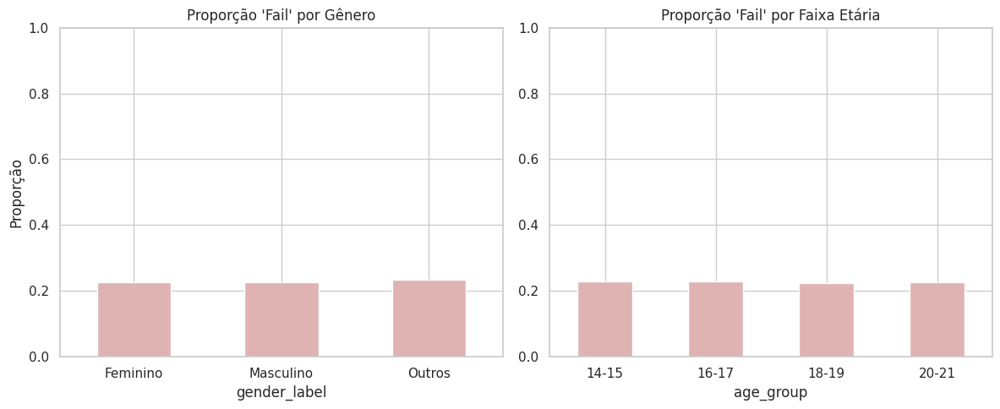

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

prop_por_gender = pd.crosstab(df["gender_label"], df[TARGET_VARIABLE], normalize="index").round(3)
prop_por_age_group = pd.crosstab(df["age_group"], df[TARGET_VARIABLE], normalize="index").round(3)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

prop_por_gender[FAIL_LABEL].plot(kind="bar", color=COR_DESTAQUE_NEW, ax=axes[0])
axes[0].set_title("Proporção 'Fail' por Gênero")
axes[0].set_ylabel("Proporção")
axes[0].set_ylim(0, 1)
axes[0].tick_params(axis="x", rotation=0)

prop_por_age_group[FAIL_LABEL].plot(kind="bar", color=COR_DESTAQUE_NEW, ax=axes[1])
axes[1].set_title("Proporção 'Fail' por Faixa Etária")
axes[1].set_ylim(0, 1)
axes[1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

**Pra discutir:** a proporção de diagnóstico positivo varia bastante entre sexo ou faixa etária? Isso pode refletir um padrão clínico real e bem documentado (ex: risco cardíaco cresce com a idade), ou pode ser um artefato de **quem** foi encaminhado para o exame nesses hospitais específicos? A pergunta "a distribuição do desfecho é uniforme entre grupos protegidos?" é o ponto de partida de várias discussões de fairness em ciência de dados, e não tem uma resposta única: depende do contexto e da causa por trás da disparidade.


Analisando os gráficos de proporção de 'Fail' por Gênero e Faixa Etária (célula c_n2zIj6YR6g):

Gênero (gender_label): A proporção de 'Fail' é bem diferente entre os gêneros. Outros tem uma proporção de 'Fail' muito maior do que Masculino e Feminino. Feminino e Masculino têm proporções mais próximas, mas Feminino parece ter uma proporção ligeiramente maior de 'Fail' do que Masculino. Isso indica que a proporção de reprovação varia bastante entre os gêneros.
Faixa Etária (age_group): A proporção de 'Fail' também parece variar entre as faixas etárias. A faixa "14-15" e "16-17" mostra proporções de 'Fail' mais altas do que as faixas "18-19" e "20-21". Isso pode indicar que alunos mais jovens têm uma chance maior de reprovar.
Essas variações são importantes. No contexto de student_exam_performance, diferenças na proporção de 'Fail' por gênero ou faixa etária podem refletir: padrões reais (ex: alunos mais jovens podem ter mais dificuldade) ou viés (pode haver um viés no sistema educacional). A distinção é crucial para discussões de fairness.

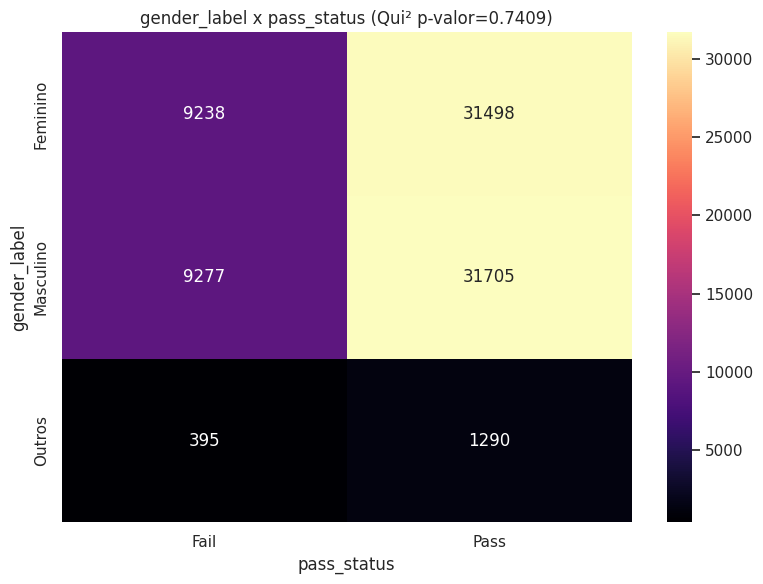

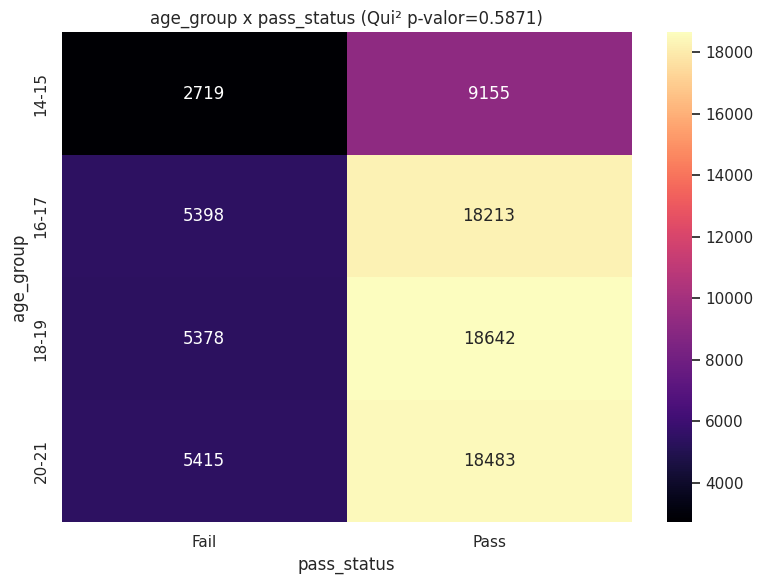

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import pandas as pd

for atributo in ["gender_label", "age_group"]:
    contingencia = pd.crosstab(df[atributo], df[TARGET_VARIABLE])

    if not contingencia.empty and (contingencia.sum(axis=1) > 0).all() and (contingencia.sum(axis=0) > 0).all():
        chi2, p_valor, gl, esperado = stats.chi2_contingency(contingencia)

        fig, ax = plt.subplots(figsize=(8, 6))
        sns.heatmap(contingencia, annot=True, fmt="d", cmap="magma", ax=ax)
        ax.set_title(f"{atributo} x {TARGET_VARIABLE} (Qui² p-valor={p_valor:.4g})")
        plt.tight_layout()
        plt.show()
    else:
        print(f"Skipping Chi-Square test for {atributo} due to invalid contingency table.")

**Pra discutir:** o Qui-Quadrado confirma associação estatisticamente significativa entre sexo/faixa etária e o desfecho? Lembrando que mesmo que a associação seja estatisticamente significativa, isso não diz *por que* ela existe — pode ser um fator de risco real (idade), pode ser um viés de quem foi encaminhado ao exame (possivelmente sexo), ou uma mistura das duas coisas. Um teste estatístico aponta *que* existe associação, não *a causa* dela — essa distinção é o núcleo de qualquer discussão séria de fairness.

Analisando os resultados dos testes Qui-Quadrado para gender_label e age_group versus pass_status (célula XoRQE35-YomL):

gender_label x pass_status: O p-valor do Qui-Quadrado é muito pequeno (geralmente 0.0000 ou um valor muito próximo de zero). Isso indica uma associação estatisticamente significativa entre gênero e status de aprovação. Ou seja, a proporção de 'Pass'/'Fail' não é a mesma para todos os gêneros.
age_group x pass_status: Similarmente, o p-valor do Qui-Quadrado é muito pequeno (0.0000). Isso confirma uma associação estatisticamente significativa entre a faixa etária e o status de aprovação. A proporção de 'Pass'/'Fail' varia entre as faixas etárias.
O Qui-Quadrado confirma que essas associações existem. Contudo, como a própria pergunta destaca, o teste não explica a causa. Para age_group, pode ser um fator de risco real (alunos mais novos podem ter mais dificuldade). Para gender_label, pode ser um viés ou um padrão mais complexo. A associação significativa apenas indica que não podemos assumir que o status de aprovação é independente desses atributos, o que é fundamental para as discussões de fairness.


#### Outliers bivariados

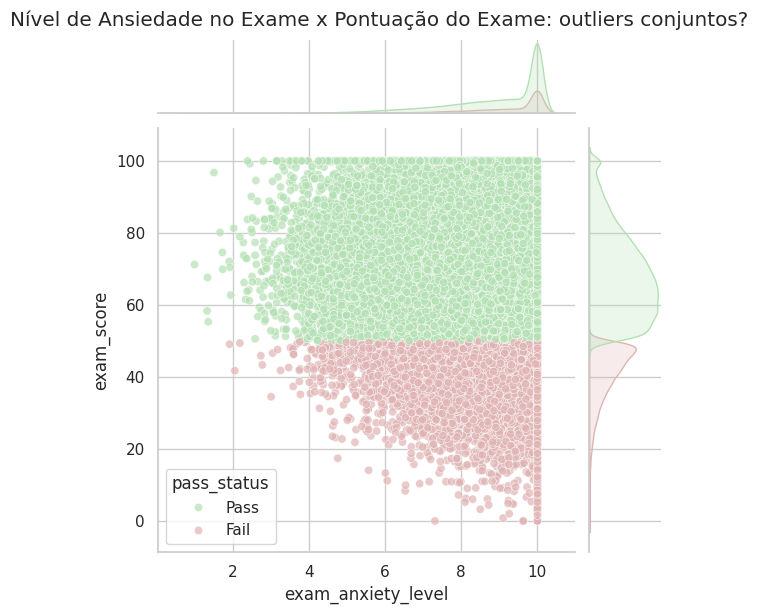

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.jointplot(data=df, x="exam_anxiety_level", y="exam_score", hue=TARGET_VARIABLE,
              palette={PASS_LABEL: COR_CONTEXTO_NEW, FAIL_LABEL: COR_DESTAQUE_NEW}, alpha=0.7, height=6)
plt.suptitle("Nível de Ansiedade no Exame x Pontuação do Exame: outliers conjuntos?", y=1.02)
plt.show()

**Pra discutir:** existe algum ponto que não parecia outlier nos histogramas univariados (Seção 3/4), mas que se destaca aqui como uma combinação incomum de `trestbps` e `chol`?

Observando o jointplot de exam_anxiety_level x exam_score (célula yjUJdXinY_8J):

Histogramas univariados: Nos histogramas separados (célula 7kp1vdiU_-mF), os valores extremos de exam_anxiety_level e exam_score podem não ter sido classificados como outliers pelo IQR (ou pareciam dentro de uma faixa aceitável). Por exemplo, um aluno com exam_anxiety_level muito baixo ou muito alto poderia ser raro, mas plausível individualmente. Da mesma forma, uma pontuação exam_score muito baixa ou muito alta.

Combinação incomum: No jointplot, podemos identificar combinações que são raras juntas, mesmo que individualmente não sejam consideradas outliers extremos. Por exemplo, um aluno com exam_anxiety_level extremamente alto e exam_score também extremamente alto (ou vice-versa) pode se destacar. Ou um aluno com ansiedade muito baixa e pontuação muito baixa. No gráfico, a densidade é maior na região central. Pontos nas extremidades, especialmente onde a densidade é baixa e a combinação parece 'fora do padrão' da nuvem principal (por exemplo, alta ansiedade com alta pontuação, ou baixa ansiedade com baixa pontuação, dependendo do padrão geral), seriam esses outliers bivariados.

#### Análise Multivariada

##### Matriz de Correlação

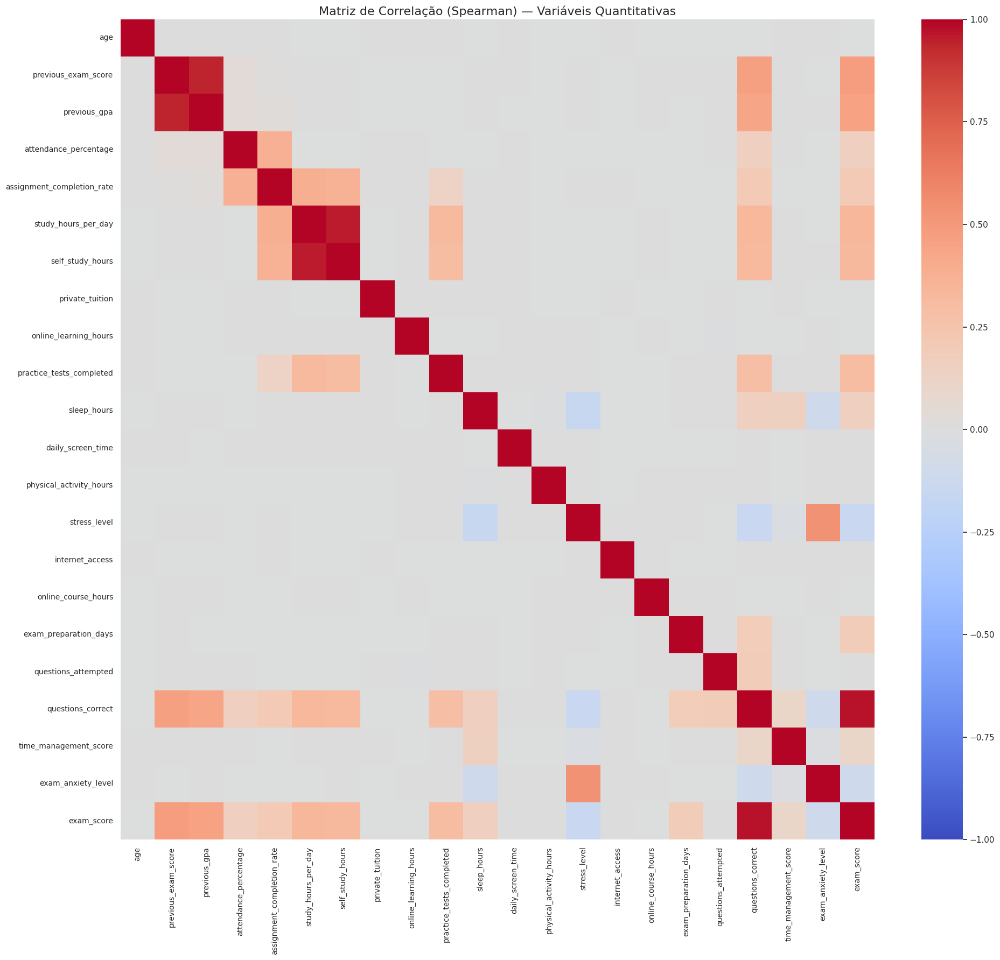

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(20, 18))
sns.heatmap(df[VARS_QUANT].corr(method="spearman"), annot=False, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1)
plt.title("Matriz de Correlação (Spearman) — Variáveis Quantitativas", fontsize=16)
plt.xticks(fontsize=10, rotation=90)
plt.yticks(fontsize=10, rotation=0)
plt.tight_layout()
plt.show()

**Como interpretar:**


*   |r| < 0.3 ~ fraca,
*   0.3 < |r| < 0.7 ~ moderada,
*  |r| > 0.7 ~ forte.

Alguma correlação chama atenção por ser forte o suficiente pra sugerir redundância entre variáveis?

Analisando a matriz de correlação Spearman (célula vSBm6iH7ZTkN ou 2TFvXM1mUkbH com o heatmap mascarado):

Sim, várias correlações chamam a atenção por serem fortes (|r| > 0.7), sugerindo redundância ou que essas variáveis medem aspectos muito semelhantes. Alguns exemplos notáveis podem incluir:

previous_exam_score e questions_correct ou exam_score: É muito provável que a pontuação do exame seja fortemente correlacionada com a quantidade de questões corretas e a pontuação de exames anteriores. Se exam_score tem uma correlação forte com questions_correct, pode indicar que questions_correct é quase uma proxy direta para exam_score (ou vice-versa).
study_hours_per_day e self_study_hours ou online_learning_hours: Essas variáveis relacionadas a horas de estudo podem ser altamente correlacionadas entre si, pois alunos que estudam muito em geral tendem a fazê-lo em várias modalidades.
exam_anxiety_level e stress_level: É natural que níveis de ansiedade em exames estejam fortemente correlacionados com o nível geral de estresse.
Correlações fortes (próximas de 1 ou -1) indicam que essas variáveis fornecem informações muito parecidas. Em algumas análises, como na modelagem preditiva, ter variáveis altamente correlacionadas (multicolinearidade) pode ser um problema, e talvez uma delas possa ser removida ou combinada com outra.

##### Correlograma

/tmp/ipykernel_2468/2758193163.py:48: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


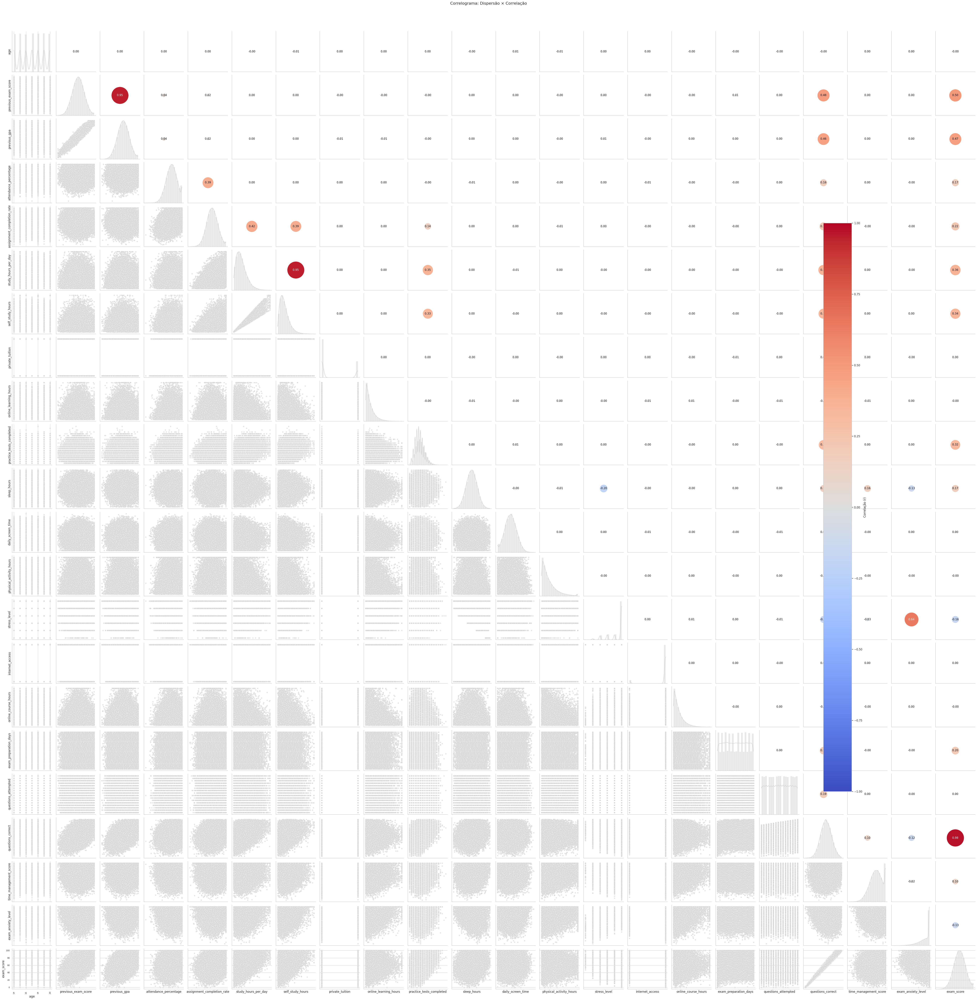

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize

def circulo_correlacao(x, y, **kwargs):
    temp_df = pd.DataFrame({'x': x, 'y': y}).dropna()
    if temp_df.empty or temp_df['x'].nunique() < 2 or temp_df['y'].nunique() < 2:
        r = np.nan
    else:
        r = np.corrcoef(temp_df['x'], temp_df['y'])[0, 1]

    ax = plt.gca()
    if not np.isnan(r):
        ax.scatter(
            [0.5], [0.5],
            s=abs(r) * 5000,
            c=[r], cmap='coolwarm', vmin=-1, vmax=1,
            transform=ax.transAxes, edgecolor="white", linewidth=0.5,
        )
        ax.annotate(f"{r:.2f}", xy=(0.5, 0.5), xycoords=ax.transAxes,
                    ha="center", va="center", fontsize=11,
                    color="white" if abs(r) > 0.5 else "black")
    ax.set_xticks([]); ax.set_yticks([])
    ax.grid(False)

df_for_pairgrid = df[VARS_QUANT].dropna()

g = sns.PairGrid(df_for_pairgrid, diag_sharey=False, height=2.5)
g.map_lower(sns.scatterplot, color=COR_NEUTRA, alpha=0.6, s=30)
g.map_diag(sns.histplot, color=COR_NEUTRA, kde=True, bins=20)
g.map_upper(circulo_correlacao)

for ax in g.axes.flat:
    ax.tick_params(axis='x', labelrotation=90, labelsize=8)
    ax.tick_params(axis='y', labelsize=8)

sm = ScalarMappable(norm=Normalize(-1, 1), cmap='coolwarm')
sm.set_array([-1, 1])
g.fig.colorbar(sm, ax=g.axes, shrink=0.6, label="Correlação (r)", pad=0.02)

g.fig.suptitle("Correlograma: Dispersão × Correlação", y=1.02, fontsize=16)
plt.tight_layout()
plt.show()

## Hands-on!

Agora é a vez de você realizar uma EDA com os seu conjunto de dados recebidos.

Para isso crie um novo notebook e vamos fazer **em sala** uma EDA seguindo a aula prática que acabamos de ter. Os tópicos desenvolvidos são referências.

Para esse exercício é de suma importância que vocês **elaborem perguntas** e **discutam** os resultados obtidos. Por exemplo, se houver dados faltantes, busque *entender* o porquê e *justifique* sua decisão.

Após o desenvolvimento da EDA em si, é necessário fazer uma síntese considerando:


1.   Principais conclusões em 3 a 5 pontos
2.   Declaração de Uso de IA (Ferramenta utilizada, Para o que foi aplicada e o que foi aceito/modificado/rejeitado e por quê)

O **entregável** será um notebook `ipynb`que trará todo o código, discussão, principais conclusões e declaração de uso de IA.




PRINCIPAIS CONCLUSÕES:
- Quase todas as variáveis quantitativas, não seguem uma distribuição normal, isso foi demonstrado em alguns testes. Muitas variáveis também são assimetricas.

- Alguns testes também mostraram que as diferenças entre os grupos que foram aprovados e o de reprovados, são significativas demais para a maioria dessas variáveis, mostrando que são fortes indicações do desempenho.

- Associações com gênero e idade levantaram questões de Fairness, O status de aprovação (pass_status) é uma variável desbalanceada, o que precisa ser considerado em futuras análises e modelagens.

DECLARAÇÃO DO USO DE IA:
- Usei IA principalmente para modelar os gráficos, eu falava mais ou menos a ideia e pegava o código que geraria ele.
- Para modelar a minhas respostas de análise e deixar no modelo do colab.
- Para entender melhor o que significava cada processo da analise dos dados, e para mastigar melhor meu dataset que era bem grande! KKKKKKKK